# Day 4 – Inventory Management and Optimization
## Session IV: Lab Activity + Lab Exercise

| | |
|---|---|
| **Name** | Krishna Mathur |
| **Enrollment ID** | AS25DXB018 |
| **Program** | MAIB, September 2025 |
| **Course** | AI in Operations |
| **Professor** | Prof. Dr. Sandip Kumar Roy |
| **Task** | Day 4 – Inventory Management and Optimization, Session IV Lab Activity + Lab Exercise |
| **Date** | 13 November 2026 |

## ✅ Requirements Checklist

**PART A: LAB ACTIVITY – Inventory Prioritization for a Retail Chain**
- [x] **A1.** ABC classification on annual consumption value (annual usage × unit cost): sort descending, cumulative %, assign A/B/C (reference: A ≈ 70–80 % of value from ≈ 20 % of items; B ≈ 15–25 % from ≈ 30 %; C ≈ 5–10 % from ≈ 50 %).
- [x] **A2.** Decision tree classifier predicting ABC category from annual usage, unit cost, lead time, past demand. Report split, accuracy, confusion matrix, classification report, feature importances, tree plot.
- [x] **A3.** Linear regression forecasting future demand from historical usage. Report coefficients, R², MAE, RMSE, actual-vs-predicted plot.
- [x] **A4.** Safety Stock = Z × σ × √Lead Time, 95 % service level (Z = 1.65), σ = 10 % of predicted demand. Show formula, per-item computation, summary table.
- [x] **A5.** Visualise ABC distribution (Pareto with cumulative % line, category counts, value share) and safety stock levels (by item and by class).
- [x] **A6.** Address learning outcomes: how AI enhances traditional inventory models; classification and regression for operational decisions; visualising and interpreting inventory risk buffers.

**PART B: LAB EXERCISE – Advanced Service-Level Trade-Off Simulation (Multi-Product Inventory Strategy)**
- [x] **B1.** Products A, B, C with unique demand, variability, lead time, holding cost per unit (parameter table).
- [x] **B2.** Service levels simulated from 80 % to 99 %.
- [x] **B3.** Z-scores matched to service levels (`scipy.stats.norm.ppf`).
- [x] **B4.** Safety Stock = Z × σ × √Lead Time; Holding Cost = Safety Stock × Holding Cost per Unit.
- [x] **B5.** ONE figure, 3 side-by-side subplots (Product A | B | C) titled *"Service Level Trade-offs in Inventory Optimization"*; x = Service Level (80–99 %); y = Units / Cost; **blue** = Safety Stock; **green** = Holding Cost; legend in each subplot; same y-scale for comparability.
- [x] **B6.** Results: quantify how service-level decisions affect buffers and cost (table at 80/90/95/99 % and % increase from 95 % to 99 %); compare trade-offs across products; show non-linear safety stock growth, rising holding cost, product variation; recommend a service level per product using the visuals.
- [x] **B7.** Sensitivity of safety stock to lead time and demand variability.

**ADDITIONAL (professor's request)**
- [x] **A7.** Plots *before AI* (traditional) vs *after AI* for classification, demand forecast and safety stock.
- [x] **B8.** Plots *before AI* (uniform service level) vs *after AI* (differentiated, data-driven service levels).

## 1. Objective

- **Part A (Lab Activity):** Help a retail chain *automate inventory prioritisation and buffer planning* by combining (i) classical **ABC analysis**, (ii) a **decision tree** that predicts the ABC class from item attributes, (iii) a **linear regression** that forecasts demand, and (iv) a statistical **safety-stock** rule tied to a 95 % service level.
- **Part B (Lab Exercise):** Analyse how the **service level** chosen for a product changes its **safety stock** and **holding cost**, how this differs across three products with different demand, variability, lead time and holding cost, and recommend a service level for each product.

## 2. Problem Statement

A retail chain stocks thousands of SKUs. Treating every SKU the same wastes working capital on slow, low-value items and under-protects the few items that drive most of the revenue. The inventory manager needs to:

1. **Prioritise** items by their annual consumption value (ABC analysis) and learn a model that can classify *new* items automatically.
2. **Forecast** next-period demand from historical usage.
3. **Size the safety stock** of every item from the forecast and its lead time, for a target service level.
4. **Decide** (Part B) how much service level is worth paying for, because every extra point of service costs additional buffer units and holding cost.

## 3. Data Description

> ⚠️ **No real retail dataset was provided with the lab.** The professor's sample notebook (`Untitled7.ipynb`) uses a hand-typed table of 7 items. 7 rows are too few to evaluate a classifier or a regression on a hold-out set, so I follow the same approach (item, usage, cost, lead time, past demand) but **generate a larger, clearly labelled SYNTHETIC dataset of 500 SKUs with `np.random.seed(42)`**. It is *not* real data and the numbers should be read as an illustration of the method, not as real retail findings.

| Column | Meaning | Unit |
|---|---|---|
| `Item` | SKU identifier | – |
| `Annual_Usage` | Units consumed in the current year | units / year |
| `Unit_Cost` | Purchase cost per unit | currency / unit |
| `Lead_Time` | Replenishment lead time | periods (as in the professor's sample) |
| `Past_Demand` | Demand observed in the previous year (historical usage) | units / year |

**Part B** uses three products (A, B, C) with a hand-specified parameter table (Section B1).

## 4. Assumptions

1. **Synthetic data** (seed 42) mimicking a retail catalogue: lognormal usage (capped at 5,000 units) and unit cost (capped at 40) – a few high-value items and a long tail of low-value ones – integer lead times 1–6, past demand = usage × random noise (mean 0.98, sd 0.08).
2. **ABC rule** exactly as in the professor's code: cumulative value ≤ 70 % → **A**, ≤ 90 % → **B**, otherwise **C**.
3. **Safety stock (Part A):** service level 95 %, **Z = 1.65** (as given on the slides; `norm.ppf(0.95)` = 1.645), σ = **10 % of predicted demand**, lead time used in the same time unit as the professor's sample (the formula is applied exactly as specified).
4. **Part B parameters** (demand, σ, lead time, holding cost) are **my own assumptions**, because the slides do not list numbers. They were calibrated so the curves have the same scale and ordering (B > A > C) as the reference chart on slide 33. Units: demand and σ in *units per period (week)*, lead time in *periods*, holding cost in *currency per unit per period*.
5. Demand during the lead time is **normally distributed** with mean μ·L and standard deviation σ·√L; demand is independent across periods.
6. **Recommendation rule (B6):** a planner tolerance of **15 currency units of extra holding cost per +1 percentage-point of service level** (an assumption – no stock-out cost was supplied). A sensitivity of this assumption is shown.

## 5. Methodology

| Step | Method | Library |
|---|---|---|
| A1 | Annual value = usage × cost → sort → cumulative % → 70/20/10 rule | `pandas` |
| A2 | Decision tree classifier (stratified 70/30 split, depth chosen by cross-validation on the training set) | `sklearn.tree` |
| A3 | Simple linear regression `Past_Demand → Annual_Usage` (70/30 split; R², MAE, RMSE) | `sklearn.linear_model` |
| A4 | Safety stock = Z · σ · √LT with Z = 1.65 | `numpy` |
| A5 | Pareto, count, value-share and safety-stock charts | `matplotlib` |
| B1–B4 | Parameter table → Z via `norm.ppf` (80–99 %) → safety stock and holding cost, plus a Monte-Carlo check | `scipy.stats`, `numpy` |
| B5–B6 | 3-panel trade-off figure, comparison tables, marginal-cost analysis and recommendation | `matplotlib` |
| B7 | Sensitivity to lead time and demand variability (curves + heat-maps) | `matplotlib`, `seaborn` |

### Environment set-up
All packages used here are pre-installed in Google Colab; the first cell only makes sure they are present (it is silent when everything is already installed). No file paths are absolute – all data is generated inside the notebook and results are written to the relative folders `data/` and `outputs/`.

In [1]:
!pip install -q numpy pandas scipy scikit-learn matplotlib seaborn

import sys, sklearn, scipy, numpy, pandas, matplotlib
print("Python      :", sys.version.split()[0])
print("numpy       :", numpy.__version__)
print("pandas      :", pandas.__version__)
print("scipy       :", scipy.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib  :", matplotlib.__version__)
print("Environment ready.")

Python      : 3.14.7
numpy       : 2.5.4
pandas      : 3.1.1
scipy       : 1.18.1
scikit-learn: 1.9.1
matplotlib  : 3.11.2
Environment ready.


### Imports, global settings and colour palette
Same library set as the professor's sample (`pandas`, `numpy`, `matplotlib`, `sklearn`, `scipy.stats.norm`) plus `seaborn` for heat-maps. A fixed seed (42) makes every number reproducible.

In [2]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             r2_score, mean_absolute_error, mean_squared_error)
from scipy.stats import norm

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

# consistent palette: ABC classes (Part A) and fixed semantic colours for Part B
PAL = {"A": "#D1495B", "B": "#EDAE49", "C": "#00798C"}
BLUE, GREEN = "tab:blue", "tab:green"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 10})
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.width", 160)

metrics = {}          # collected key numbers (exported at the end)
def put(key, value):
    if isinstance(value, (np.integer,)): value = int(value)
    elif isinstance(value, (np.floating,)): value = float(value)
    metrics[key] = value

Z_95 = 1.65           # given on the slides for a 95 % service level
print("Setup complete. Seed =", SEED, "| Z (95 %) used in Part A =", Z_95)

Setup complete. Seed = 42 | Z (95 %) used in Part A = 1.65


---
# PART A – LAB ACTIVITY: Inventory Prioritization for a Retail Chain

## A0. Baseline – the professor's 7-item sample
Before scaling up, I reproduce the professor's pipeline on his own 7-item table (slide 29) with the same logic (ABC → decision tree → linear regression → safety stock, in-sample, Z = 1.65). This confirms I understand the reference implementation; the full analysis in A1–A6 then uses a larger dataset so the models can be evaluated on unseen items.

In [3]:
sample = pd.DataFrame({
    'Item': ['A1', 'A2', 'A3', 'B1', 'B2', 'C1', 'C2'],
    'Annual_Usage': [1000, 800, 600, 400, 300, 100, 50],
    'Unit_Cost': [10, 12, 8, 5, 6, 2, 1],
    'Lead_Time': [2, 2, 2, 3, 3, 4, 4],
    'Past_Demand': [950, 820, 610, 390, 310, 120, 60]})

sample['Annual_Value'] = sample['Annual_Usage'] * sample['Unit_Cost']
sample = sample.sort_values('Annual_Value', ascending=False)
sample['Cumulative%'] = sample['Annual_Value'].cumsum() / sample['Annual_Value'].sum() * 100
sample['ABC_Category'] = np.where(sample['Cumulative%'] <= 70, 'A',
                          np.where(sample['Cumulative%'] <= 90, 'B', 'C'))

feat = ['Annual_Usage', 'Unit_Cost', 'Lead_Time', 'Past_Demand']
tree_s = DecisionTreeClassifier(random_state=SEED).fit(sample[feat], sample['ABC_Category'])
sample['Predicted_ABC'] = tree_s.predict(sample[feat])

reg_s = LinearRegression().fit(sample[['Past_Demand']], sample['Annual_Usage'])
sample['Predicted_Demand'] = reg_s.predict(sample[['Past_Demand']]).round()
sample['Std_Dev'] = sample['Predicted_Demand'] * 0.10
sample['Safety_Stock'] = (Z_95 * sample['Std_Dev'] * np.sqrt(sample['Lead_Time'])).round()

display(sample[['Item', 'Annual_Value', 'Cumulative%', 'ABC_Category', 'Predicted_ABC',
                'Predicted_Demand', 'Lead_Time', 'Safety_Stock']].reset_index(drop=True))

,Item,Annual_Value,Cumulative%,ABC_Category,Predicted_ABC,Predicted_Demand,Lead_Time,Safety_Stock
0,A1,10000,35.15,A,A,968.00,2,226.00
1,A2,9600,68.89,A,A,833.00,2,194.00
2,A3,4800,85.76,B,B,614.00,2,143.00
3,B1,2000,92.79,C,C,386.00,3,110.00
4,B2,1800,99.12,C,C,302.00,3,86.00
5,C1,200,99.82,C,C,105.00,4,35.00
6,C2,50,100.00,C,C,43.00,4,14.00


**Business interpretation – baseline.**
- A1 and A2 (the two high-value items) are class **A**, A3 falls into **B** because it crosses the 70 % mark, and the four low-value items are **C** – the professor's rule is reproduced exactly (70 % → A, next 20 % → B, rest → C).
- The decision tree reproduces every label (in-sample), and the buffers are largest for the fast-moving items (A1: 226 units, A2: 194 units) and smallest for C2 (14 units).
- With only 7 rows a tree can always memorise the labels, so this accuracy says nothing about generalisation. That is why the rest of the lab uses a larger dataset and a **hold-out test set**.

## Dataset generation (synthetic, seed = 42)
I generate 500 SKUs: lognormal usage and unit cost (a handful of expensive/fast items and a long tail of cheap/slow ones, typical of retail), integer lead times, and `Past_Demand` as last year's demand = usage × noise. The generator was tuned (not the results) so that the resulting ABC split is close to the classical reference proportions.

*Optional:* set `USE_OWN_CSV = True` to upload your own file with the same five columns instead.

In [4]:
USE_OWN_CSV = False      # True -> upload a CSV with columns Item, Annual_Usage, Unit_Cost, Lead_Time, Past_Demand

if USE_OWN_CSV:
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(next(iter(uploaded)))
else:
    n_items = 500
    np.random.seed(SEED)
    base_usage = np.random.lognormal(mean=np.log(500), sigma=1.1, size=n_items)
    annual_usage = np.clip(np.round(base_usage), 20, 5000).astype(int)      # cap at a realistic maximum
    unit_cost = np.clip(np.round(np.random.lognormal(mean=np.log(6), sigma=0.9, size=n_items), 2), 0.5, 40.0)
    lead_time = np.random.choice([1, 2, 3, 4, 5, 6], size=n_items, p=[.10, .25, .25, .20, .12, .08])
    past_demand = np.round(annual_usage * np.random.normal(0.98, 0.08, n_items)).astype(int)
    df = pd.DataFrame({'Item': [f"SKU_{i+1:03d}" for i in range(n_items)],
                       'Annual_Usage': annual_usage, 'Unit_Cost': unit_cost,
                       'Lead_Time': lead_time, 'Past_Demand': past_demand})

df.to_csv("data/inventory_synthetic_data.csv", index=False)
put("n_items", len(df))
print("SYNTHETIC dataset (not real data) | rows, columns:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
display(df.head(8))
display(df.describe().T)

SYNTHETIC dataset (not real data) | rows, columns: (500, 5)
Missing values: 0


,Item,Annual_Usage,Unit_Cost,Lead_Time,Past_Demand
0,SKU_001,863,13.81,2,821
1,SKU_002,429,33.46,2,427
2,SKU_003,1019,1.70,4,889
3,SKU_004,2670,9.96,4,2409
4,SKU_005,386,3.34,1,415
5,SKU_006,386,3.87,6,358
6,SKU_007,2841,3.52,1,2546
7,SKU_008,1163,2.76,3,1190


,count,mean,std,min,25%,50%,75%,max
Annual_Usage,500.00,855.29,"1,017.17",20.00,231.75,507.00,"1,007.25","5,000.00"
Unit_Cost,500.00,8.85,8.24,0.53,3.51,6.16,10.78,40.00
Lead_Time,500.00,3.26,1.43,1.00,2.00,3.00,4.00,6.00
Past_Demand,500.00,840.98,"1,002.42",20.00,228.25,494.50,978.25,"5,642.00"


**Reading the data.** The dataset has 500 SKUs and no missing values. Usage and unit cost are right-skewed (mean annual usage ≈ 855 units vs median ≈ 507; a few items are priced at 20–40 per unit while the median is ≈ 6), which is the pattern that makes ABC analysis worthwhile: a minority of SKUs will dominate the annual spend. Remember that this is **synthetic data**, generated with seed 42 and saved to `data/inventory_synthetic_data.csv`.

## A1. ABC Classification on Annual Consumption Value
**Steps:** (1) annual value = `Annual_Usage × Unit_Cost`; (2) sort descending; (3) cumulative % of total value; (4) assign **A** (cumulative ≤ 70 %), **B** (≤ 90 %), **C** (rest) – the rule from the professor's code. The summary table compares the result with the textbook reference proportions.

In [5]:
df['Annual_Value'] = df['Annual_Usage'] * df['Unit_Cost']
df = df.sort_values(by='Annual_Value', ascending=False).reset_index(drop=True)
df['Value_Share%'] = df['Annual_Value'] / df['Annual_Value'].sum() * 100
df['Cumulative%'] = df['Annual_Value'].cumsum() / df['Annual_Value'].sum() * 100
df['Item_Rank%'] = (df.index + 1) / len(df) * 100        # cumulative % of items

def classify(row):
    if row['Cumulative%'] <= 70:
        return 'A'
    elif row['Cumulative%'] <= 90:
        return 'B'
    else:
        return 'C'
df['ABC_Category'] = df.apply(classify, axis=1)

abc = (df.groupby('ABC_Category')
         .agg(Items=('Item', 'count'), Annual_Value=('Annual_Value', 'sum'))
         .assign(**{'Items_%': lambda t: t['Items'] / t['Items'].sum() * 100,
                    'Value_%': lambda t: t['Annual_Value'] / t['Annual_Value'].sum() * 100}))
abc['Reference (items / value)'] = ['~20% / 70-80%', '~30% / 15-25%', '~50% / 5-10%']
for c in 'ABC':
    put(f'abc_{c}_items', abc.loc[c, 'Items']); put(f'abc_{c}_items_pct', abc.loc[c, 'Items_%'])
    put(f'abc_{c}_value', abc.loc[c, 'Annual_Value']); put(f'abc_{c}_value_pct', abc.loc[c, 'Value_%'])
put('total_value', df['Annual_Value'].sum())

print("Top 10 items by annual consumption value:")
display(df[['Item', 'Annual_Usage', 'Unit_Cost', 'Annual_Value', 'Cumulative%', 'ABC_Category']].head(10))
print("ABC summary vs reference proportions:")
display(abc)

Top 10 items by annual consumption value:


,Item,Annual_Usage,Unit_Cost,Annual_Value,Cumulative%,ABC_Category
0,SKU_210,5000,27.62,"138,100.00",3.78,A
1,SKU_180,5000,18.84,"94,200.00",6.36,A
2,SKU_168,4028,23.23,"93,570.44",8.92,A
3,SKU_123,2339,32.64,"76,344.96",11.01,A
4,SKU_421,4824,15.77,"76,074.48",13.09,A
5,SKU_235,5000,15.15,"75,750.00",15.17,A
6,SKU_072,2715,27.13,"73,657.95",17.18,A
7,SKU_178,2474,29.04,"71,844.96",19.15,A
8,SKU_394,3749,17.19,"64,445.31",20.92,A
9,SKU_142,2106,26.95,"56,756.70",22.47,A


ABC summary vs reference proportions:


,Items,Annual_Value,Items_%,Value_%,Reference (items / value)
ABC_Category,,,,,
A,103,"2,556,758.46",20.60,70.00,~20% / 70-80%
B,142,"729,855.06",28.40,19.98,~30% / 15-25%
C,255,"366,124.83",51.00,10.02,~50% / 5-10%


**Business interpretation – ABC classification.**
- **Class A:** 103 items (20.6 % of the catalogue) generate **70.0 %** of annual consumption value → tight control, frequent review, accurate forecasts and a high service level.
- **Class B:** 142 items (28.4 %) generate 20.0 % of value → moderate control, periodic review.
- **Class C:** 255 items (51.0 %) generate only **10.0 %** of value → simple rules (e.g. bulk ordering, low review frequency).
- The split (≈ 21 % / 28 % / 51 % of items carrying 70 % / 20 % / 10 % of value) is close to the textbook Pareto reference of ~20 / ~30 / ~50 % of items. Half of the catalogue accounts for one-tenth of the spend, so management attention should not be spread evenly. The generator was tuned for this shape, so this closeness is by design and not a discovery about real retail data.
- By the professor's rule the item that crosses 70 % is placed in B, so class A carries just under 70 % (70.00 %).

## A2. Decision Tree – Predicting the ABC Category
**Goal:** learn to predict the ABC class from `Annual_Usage`, `Unit_Cost`, `Lead_Time`, `Past_Demand` so that *new* items can be classified instantly, without recomputing the whole cumulative table.

**Design:** stratified **70 / 30 train–test split** (`random_state = 42`); tree depth chosen by 5-fold cross-validation **on the training set only** (the test set is never used to tune). Reported: accuracy, confusion matrix, classification report, feature importances and the tree plot.

In [6]:
features = ['Annual_Usage', 'Unit_Cost', 'Lead_Time', 'Past_Demand']
X = df[features]
y = df['ABC_Category']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=SEED, stratify=y)
print(f"Split -> train: {len(X_train)} items (70%) | test: {len(X_test)} items (30%), stratified by ABC class")

# choose tree depth by 5-fold CV on the TRAINING set only
rows = []
for d in range(2, 9):
    cv = cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=SEED), X_train, y_train, cv=5).mean()
    rows.append({'max_depth': d, 'CV_accuracy': cv})
depth_tbl = pd.DataFrame(rows)
best_depth = int(depth_tbl.loc[depth_tbl['CV_accuracy'].round(4).idxmax(), 'max_depth'])
display(depth_tbl)
print("Selected max_depth =", best_depth)

tree = DecisionTreeClassifier(max_depth=best_depth, random_state=SEED)
tree.fit(X_train, y_train)
pred_test = tree.predict(X_test)
acc_test = accuracy_score(y_test, pred_test)
acc_train = accuracy_score(y_train, tree.predict(X_train))
put('tree_depth', best_depth); put('tree_train_n', len(X_train)); put('tree_test_n', len(X_test))
put('tree_acc_test', acc_test); put('tree_acc_train', acc_train)
print(f"\nTrain accuracy: {acc_train:.3f} | TEST accuracy: {acc_test:.3f}")

labels = ['A', 'B', 'C']
cm = confusion_matrix(y_test, pred_test, labels=labels)
print("\nConfusion matrix (rows = actual, columns = predicted):")
display(pd.DataFrame(cm, index=[f'Actual {l}' for l in labels], columns=[f'Pred {l}' for l in labels]))
print("Classification report (test set):")
print(classification_report(y_test, pred_test, labels=labels, digits=3))
rep = classification_report(y_test, pred_test, labels=labels, output_dict=True)
for l in labels:
    put(f'tree_f1_{l}', rep[l]['f1-score']); put(f'tree_recall_{l}', rep[l]['recall']); put(f'tree_prec_{l}', rep[l]['precision'])
put('tree_macro_f1', rep['macro avg']['f1-score'])

imp = pd.Series(tree.feature_importances_, index=features).sort_values(ascending=False)
print("Feature importances:")
display(imp.rename('Importance').to_frame())
for f_, v_ in imp.items(): put(f'imp_{f_}', v_)

# in-sample prediction for every item (as in the professor's code)
df['Predicted_ABC'] = tree.predict(df[features])
put('tree_all_agree_pct', (df['Predicted_ABC'] == df['ABC_Category']).mean() * 100)

Split -> train: 350 items (70%) | test: 150 items (30%), stratified by ABC class


,max_depth,CV_accuracy
0,2,0.69
1,3,0.75
2,4,0.84
3,5,0.85
4,6,0.86
5,7,0.86
6,8,0.87


Selected max_depth = 8

Train accuracy: 0.997 | TEST accuracy: 0.907

Confusion matrix (rows = actual, columns = predicted):


,Pred A,Pred B,Pred C
Actual A,27,4,0
Actual B,5,35,3
Actual C,0,2,74


Classification report (test set):
              precision    recall  f1-score   support

           A      0.844     0.871     0.857        31
           B      0.854     0.814     0.833        43
           C      0.961     0.974     0.967        76

    accuracy                          0.907       150
   macro avg      0.886     0.886     0.886       150
weighted avg      0.906     0.907     0.906       150

Feature importances:


,Importance
Unit_Cost,0.49
Annual_Usage,0.27
Past_Demand,0.19
Lead_Time,0.04


**Business interpretation – decision tree.**
- **Split:** 350 training items (70 %) and 150 unseen test items (30 %), stratified so that A, B and C keep the same proportions in both parts.
- **Accuracy:** **0.907** on the test set (90.7 %) vs 0.997 on the training set. The gap shows that the tree (depth 8, chosen by cross-validation) fits the training data almost perfectly and loses about nine points on new items – a mild overfit that is worth knowing about.
- **Confusion matrix:** all mistakes are between *neighbouring* classes (A↔B: 4 + 5 items; B↔C: 3 + 2 items). **No A item was predicted as C and no C item as A**, so the model never makes a gross error – it only blurs the class boundaries.
- **Per-class quality:** C is classified best (F1 = 0.967), A is good (F1 = 0.857) and **B is the hardest** (F1 = 0.833) because it is the "middle" class squeezed between two boundaries. Macro-F1 = 0.886.
- **Feature importance:** `Unit_Cost` (0.49), `Annual_Usage` (0.27) and `Past_Demand` (0.19) drive the prediction; `Lead_Time` is almost irrelevant (0.04). This is exactly what we expect: the ABC class is defined by *usage × cost*, so price and volume matter and lead time does not.

#### A2 (continued) – Confusion-matrix heat-map and feature importances

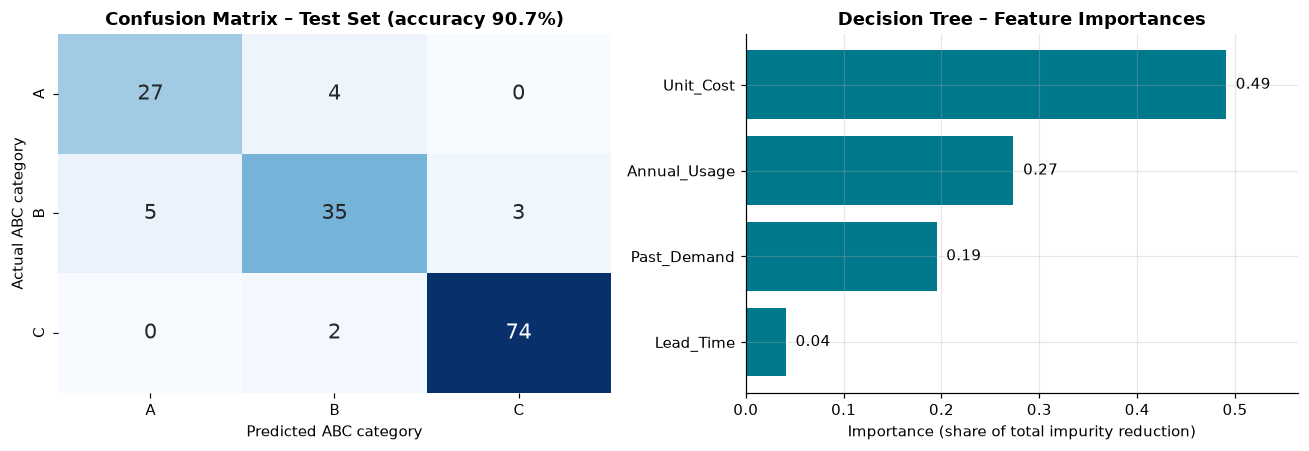

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels,
            cbar=False, ax=axes[0], annot_kws={'size': 14})
axes[0].set_title(f'Confusion Matrix – Test Set (accuracy {acc_test:.1%})')
axes[0].set_xlabel('Predicted ABC category'); axes[0].set_ylabel('Actual ABC category'); axes[0].grid(False)

axes[1].barh(imp.index[::-1], imp.values[::-1], color='#00798C')
for i, v in enumerate(imp.values[::-1]):
    axes[1].text(v + 0.01, i, f'{v:.2f}', va='center')
axes[1].set_title('Decision Tree – Feature Importances')
axes[1].set_xlabel('Importance (share of total impurity reduction)'); axes[1].set_xlim(0, imp.max() * 1.15)
plt.tight_layout()
plt.savefig('outputs/A2_confusion_matrix_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

**Business interpretation – confusion matrix and importances.** The diagonal dominates the heat-map (136 of 150 test items correct). The planner can trust a predicted "C" almost blindly (precision 0.96), whereas a predicted "B" deserves a quick manual check because it is the most frequently confused class. The importance bars confirm that the model has learned the economic logic of ABC analysis (cost and volume) rather than something spurious such as lead time.

#### A2 (continued) – Tree plot
The fitted tree (top three levels shown for readability), with the split rule, class counts and majority class in every node (colours = predicted class).

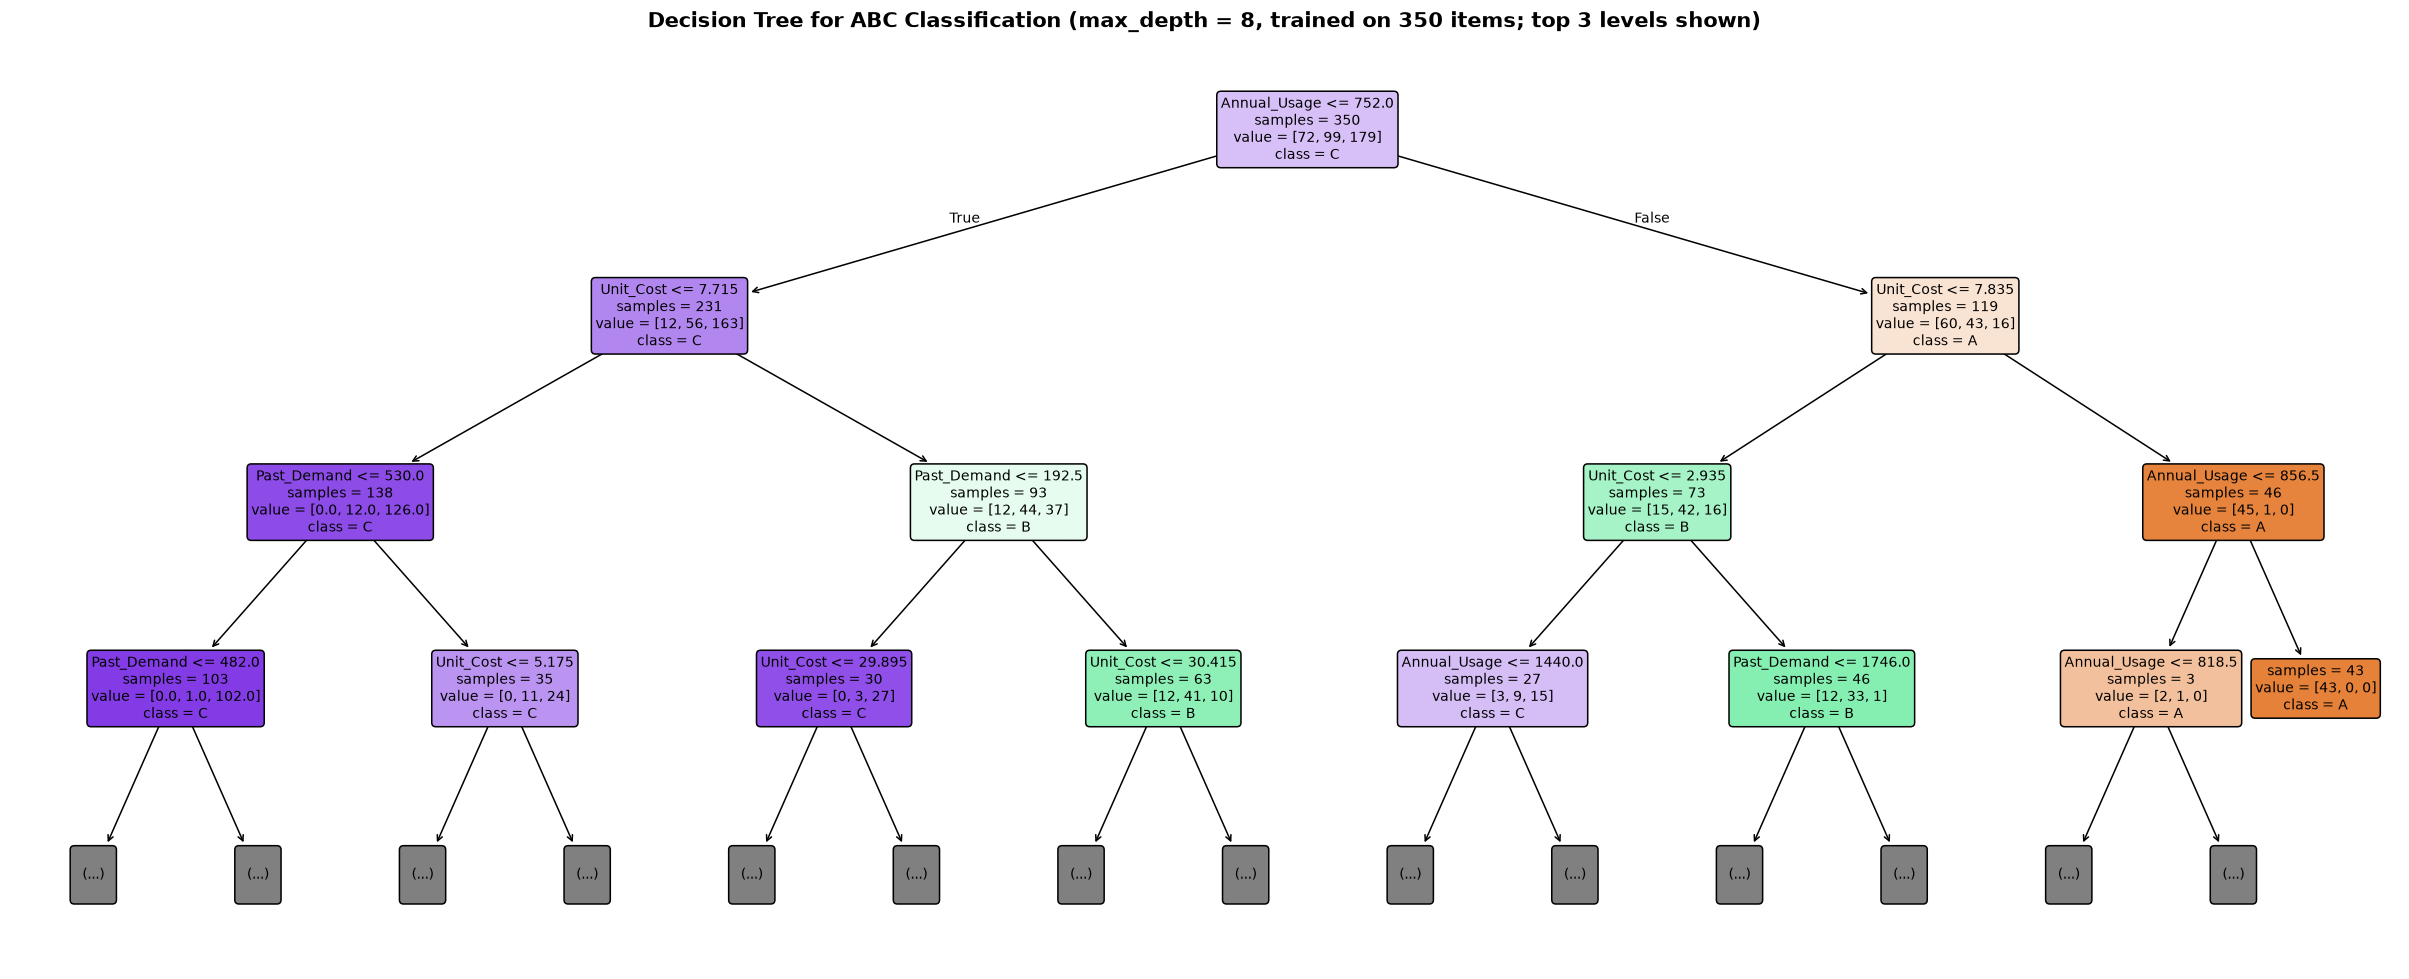

Number of leaves in the full tree: 35 | tree depth: 8


In [8]:
plt.figure(figsize=(28, 11))
plot_tree(tree, feature_names=features, class_names=labels, filled=True, rounded=True,
          fontsize=9, impurity=False, proportion=False, max_depth=3)   # top 3 levels shown for readability
plt.title(f'Decision Tree for ABC Classification (max_depth = {best_depth}, trained on {len(X_train)} items; top 3 levels shown)', fontsize=14)
plt.savefig('outputs/A2_decision_tree.png', dpi=130, bbox_inches='tight')
plt.show()
print("Number of leaves in the full tree:", tree.get_n_leaves(), "| tree depth:", tree.get_depth())
put('tree_leaves', tree.get_n_leaves())

**Business interpretation – tree structure.** The first split is on **`Annual_Usage`** (≈ 752 units/year). Low-usage items (231 of 350 training items) go mostly to C unless `Unit_Cost` is high (> ≈ 7.7 sends them towards B), while the high-usage branch (119 items, 60 of them A) is separated by `Unit_Cost` (≈ 7.8) and a second usage threshold (≈ 857): **usage above ≈ 860 units and unit cost above ≈ 7.8 gives a pure class-A leaf (43 of 43 training items)**. These are human-readable rules a buyer can apply without software. The full tree has 35 leaves; only the top three levels are drawn here to keep the figure legible.

## A3. Linear Regression – Demand Forecast from Historical Usage
**Goal:** forecast demand from historical usage. As in the professor's code the model is `Annual_Usage = β₀ + β₁ · Past_Demand` (last year's demand as the predictor of this year's demand).

**Design:** the model is trained on a **70 / 30 split** and evaluated on unseen items (R², MAE, RMSE, with the training scores for comparison). The final model is then refitted on all items to produce `Predicted_Demand` for every SKU, which feeds the safety-stock step.

Equation: Annual_Usage = 8.199 + 1.0013 x Past_Demand
Coefficient (slope)   : 1.0013
Intercept             : 8.199
R2   train = 0.9904 | test = 0.9908
MAE  train = 50.52 | test = 60.63 units
RMSE train = 96.65 | test = 103.44 units


,R2,MAE (units),RMSE (units)
Train (70%),0.99,50.52,96.65
Test (30%),0.99,60.63,103.44


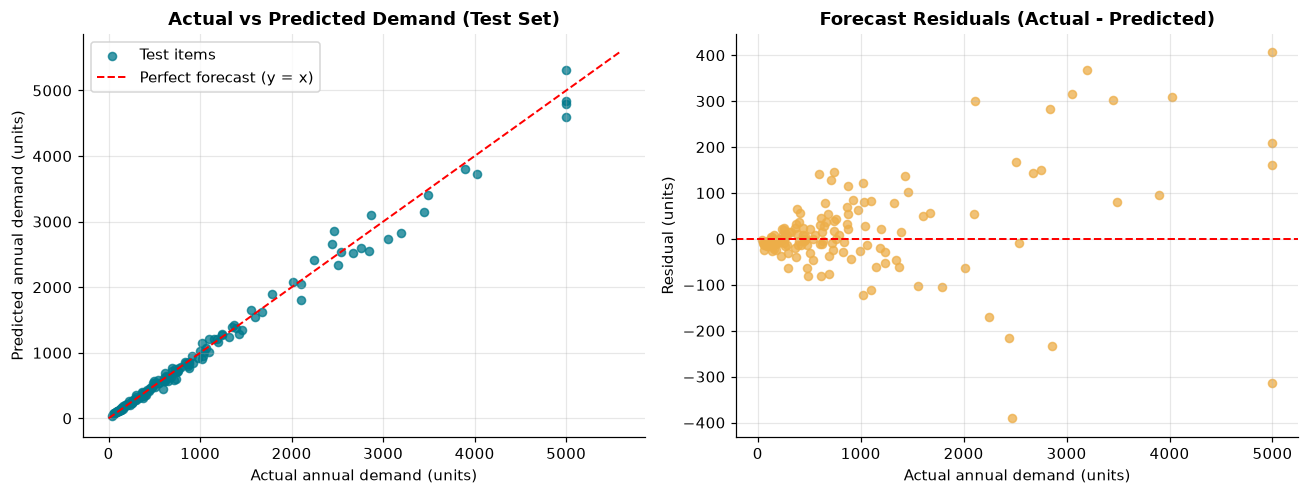

In [9]:
Xr = df[['Past_Demand']]
yr = df['Annual_Usage']
Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.30, random_state=SEED)

reg = LinearRegression().fit(Xr_train, yr_train)
yr_pred = reg.predict(Xr_test)

r2_te = r2_score(yr_test, yr_pred); mae_te = mean_absolute_error(yr_test, yr_pred)
rmse_te = np.sqrt(mean_squared_error(yr_test, yr_pred))
r2_tr = r2_score(yr_train, reg.predict(Xr_train))
mae_tr = mean_absolute_error(yr_train, reg.predict(Xr_train))
rmse_tr = np.sqrt(mean_squared_error(yr_train, reg.predict(Xr_train)))

res = pd.DataFrame({'R2': [r2_tr, r2_te], 'MAE (units)': [mae_tr, mae_te], 'RMSE (units)': [rmse_tr, rmse_te]},
                   index=['Train (70%)', 'Test (30%)'])
print(f"Equation: Annual_Usage = {reg.intercept_:.3f} + {reg.coef_[0]:.4f} x Past_Demand")
print(f"Coefficient (slope)   : {reg.coef_[0]:.4f}")
print(f"Intercept             : {reg.intercept_:.3f}")
print(f"R2   train = {r2_tr:.4f} | test = {r2_te:.4f}")
print(f"MAE  train = {mae_tr:.2f} | test = {mae_te:.2f} units")
print(f"RMSE train = {rmse_tr:.2f} | test = {rmse_te:.2f} units")
display(res)
for k, v in {'lr_coef': reg.coef_[0], 'lr_intercept': reg.intercept_, 'lr_r2_test': r2_te, 'lr_mae_test': mae_te,
             'lr_rmse_test': rmse_te, 'lr_r2_train': r2_tr, 'lr_mae_train': mae_tr, 'lr_rmse_train': rmse_tr,
             'lr_test_n': len(yr_test), 'mean_usage': yr.mean()}.items():
    put(k, v)

# final model on all items -> Predicted_Demand for every SKU (as in the professor's code)
reg_all = LinearRegression().fit(Xr, yr)
df['Predicted_Demand'] = reg_all.predict(Xr).round()
put('lr_all_coef', reg_all.coef_[0]); put('lr_all_intercept', reg_all.intercept_)
put('pred_demand_total', df['Predicted_Demand'].sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
lim = [0, max(yr_test.max(), yr_pred.max()) * 1.05]
axes[0].scatter(yr_test, yr_pred, s=28, alpha=0.75, color='#00798C', label='Test items')
axes[0].plot(lim, lim, 'r--', lw=1.3, label='Perfect forecast (y = x)')
axes[0].set_title('Actual vs Predicted Demand (Test Set)')
axes[0].set_xlabel('Actual annual demand (units)'); axes[0].set_ylabel('Predicted annual demand (units)'); axes[0].legend()

axes[1].scatter(yr_test, yr_test - yr_pred, s=28, alpha=0.75, color='#EDAE49')
axes[1].axhline(0, color='r', ls='--', lw=1.3)
axes[1].set_title('Forecast Residuals (Actual - Predicted)')
axes[1].set_xlabel('Actual annual demand (units)'); axes[1].set_ylabel('Residual (units)')
plt.tight_layout()
plt.savefig('outputs/A3_actual_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()

**Business interpretation – demand forecast.**
- **Equation:** `Annual_Usage = 8.20 + 1.0013 × Past_Demand` (test-split model). A slope of 1.001 means that next year's demand is forecast at essentially **the same level as last year's, with a ≈ 0.1 % uplift**, and the intercept is negligible.
- **R² (test) = 0.9908**: last year's demand explains ≈ 99 % of the variation in this year's demand. Train R² = 0.9904, so the model generalises – there is no overfitting.
- **Errors (test):** MAE = **60.6 units** and RMSE = **103.4 units** on items whose mean annual demand is ≈ 855 units, i.e. a typical error of ≈ 7 % of mean demand (RMSE > MAE because a few high-volume items have larger absolute errors).
- The actual-vs-predicted plot hugs the 45° line and the residuals scatter around zero with a funnel shape (errors grow with volume – larger items are harder to forecast in absolute units).
- **Caution:** this very high R² is partly a property of my synthetic data (usage was generated as a noisy copy of past demand). Real retail demand has trend and seasonality and the fit would be lower.

## A4. Safety Stock Calculation
**Formula (95 % service level):**

$$\text{Safety Stock} = Z \times \sigma \times \sqrt{\text{Lead Time}},\qquad Z = 1.65,\qquad \sigma = 10\,\% \times \text{Predicted Demand}$$

- `Z = 1.65` is the standard-normal value for a 95 % cycle service level (given on the slide).
- σ is the standard deviation of demand, assumed to be **10 % of the predicted demand** from A3.
- Lead time enters through its square root because variances add across periods.

The cell first shows one worked example, then computes the buffer for every item and summarises it by ABC class.

In [10]:
df['Std_Dev'] = df['Predicted_Demand'] * 0.10
df['Safety_Stock'] = (Z_95 * df['Std_Dev'] * np.sqrt(df['Lead_Time'])).round()

# worked example for the top item
r0 = df.iloc[0]
print("Worked example –", r0['Item'], f"(class {r0['ABC_Category']})")
print(f"  Predicted demand = {r0['Predicted_Demand']:,.0f}   ->  sigma = 10% x {r0['Predicted_Demand']:,.0f} = {r0['Std_Dev']:,.1f}")
print(f"  Lead time        = {r0['Lead_Time']}            ->  sqrt(LT) = {np.sqrt(r0['Lead_Time']):.3f}")
print(f"  Safety Stock     = {Z_95} x {r0['Std_Dev']:,.1f} x {np.sqrt(r0['Lead_Time']):.3f} = {r0['Safety_Stock']:,.0f} units\n")

print("Per-item computation (top 12 items by annual value; all 500 items are saved in outputs/):")
display(df[['Item', 'ABC_Category', 'Predicted_ABC', 'Predicted_Demand', 'Std_Dev', 'Lead_Time', 'Safety_Stock']].head(12))

ss_sum = (df.groupby('ABC_Category')
            .agg(Items=('Item', 'count'), Predicted_Demand=('Predicted_Demand', 'sum'),
                 Total_Safety_Stock=('Safety_Stock', 'sum'), Avg_Safety_Stock=('Safety_Stock', 'mean'),
                 Avg_Lead_Time=('Lead_Time', 'mean')))
ss_sum['SS_as_%_of_Demand'] = ss_sum['Total_Safety_Stock'] / ss_sum['Predicted_Demand'] * 100
ss_sum['Share_of_Total_SS_%'] = ss_sum['Total_Safety_Stock'] / ss_sum['Total_Safety_Stock'].sum() * 100
print("Summary of safety stock by ABC class:")
display(ss_sum)
total_ss = df['Safety_Stock'].sum()
print(f"TOTAL safety stock for all {len(df)} items: {total_ss:,.0f} units "
      f"({total_ss / df['Predicted_Demand'].sum():.1%} of total predicted demand)")

# value of the buffer (units x unit cost)
df['SS_Value'] = df['Safety_Stock'] * df['Unit_Cost']
ssv = df.groupby('ABC_Category')['SS_Value'].sum()
print("Safety-stock value (units x unit cost) by class:", {k: round(v) for k, v in ssv.items()}, "| total:", round(ssv.sum()))
put('ss_total', total_ss); put('ss_total_value', ssv.sum()); put('ss_pct_demand', total_ss / df['Predicted_Demand'].sum() * 100)
for c in 'ABC':
    put(f'ss_{c}_total', ss_sum.loc[c, 'Total_Safety_Stock']); put(f'ss_{c}_avg', ss_sum.loc[c, 'Avg_Safety_Stock'])
    put(f'ss_{c}_share', ss_sum.loc[c, 'Share_of_Total_SS_%']); put(f'ss_{c}_value', ssv[c])
    put(f'ss_{c}_pct_demand', ss_sum.loc[c, 'SS_as_%_of_Demand'])

Worked example – SKU_210 (class A)
  Predicted demand = 4,632   ->  sigma = 10% x 4,632 = 463.2
  Lead time        = 3            ->  sqrt(LT) = 1.732
  Safety Stock     = 1.65 x 463.2 x 1.732 = 1,324 units

Per-item computation (top 12 items by annual value; all 500 items are saved in outputs/):


,Item,ABC_Category,Predicted_ABC,Predicted_Demand,Std_Dev,Lead_Time,Safety_Stock
0,SKU_210,A,A,"4,632.00",463.20,3,"1,324.00"
1,SKU_180,A,A,"4,406.00",440.60,4,"1,454.00"
2,SKU_168,A,A,"3,750.00",375.00,4,"1,238.00"
3,SKU_123,A,A,"2,607.00",260.70,3,745.00
4,SKU_421,A,A,"4,676.00",467.60,1,772.00
5,SKU_235,A,A,"4,982.00",498.20,2,"1,163.00"
6,SKU_072,A,A,"2,823.00",282.30,5,"1,042.00"
7,SKU_178,A,A,"2,204.00",220.40,3,630.00
8,SKU_394,A,A,"3,488.00",348.80,4,"1,151.00"
9,SKU_142,A,A,"1,819.00",181.90,4,600.00


Summary of safety stock by ABC class:


,Items,Predicted_Demand,Total_Safety_Stock,Avg_Safety_Stock,Avg_Lead_Time,SS_as_%_of_Demand,Share_of_Total_SS_%
ABC_Category,,,,,,,
A,103,"207,083.00","61,302.00",595.17,3.30,29.60,48.93
B,142,"127,092.00","36,975.00",260.39,3.35,29.09,29.52
C,255,"93,469.00","26,996.00",105.87,3.20,28.88,21.55


TOTAL safety stock for all 500 items: 125,273 units (29.3% of total predicted demand)
Safety-stock value (units x unit cost) by class: {'A': 745776, 'B': 216062, 'C': 106702} | total: 1068540


**Business interpretation – safety stock.**
- The worked example shows the mechanics: Z (1.65) × σ (10 % of predicted demand) × √lead time. Longer lead times and higher forecast demand both enlarge the buffer.
- **Total safety stock = 125,273 units** (≈ 29.3 % of total predicted demand). Class **A holds 61,302 units (48.9 % of all buffer units)**, B 36,975 units (29.5 %) and C 26,996 units (21.5 %).
- Because σ is a fixed 10 % of demand, the buffer is ≈ 29 % of predicted demand in *every* class; the classes differ in **absolute size** (average buffer: A 595, B 260, C 106 units per item).
- **Money tied up:** valued at unit cost the buffer is ≈ 1,068,540 currency units, and **class A alone accounts for 70 %** of it (745,776) although it is only 21 % of the items. This is where working capital is locked up and where better forecasts or shorter lead times pay off most.

## A5. Visualising the ABC Distribution and Safety Stock Levels
Three figures: **(1)** Pareto chart (value bars + cumulative % line with the 70 % / 90 % cut-offs), **(2)** category counts and value share, **(3)** safety stock by item and by class.

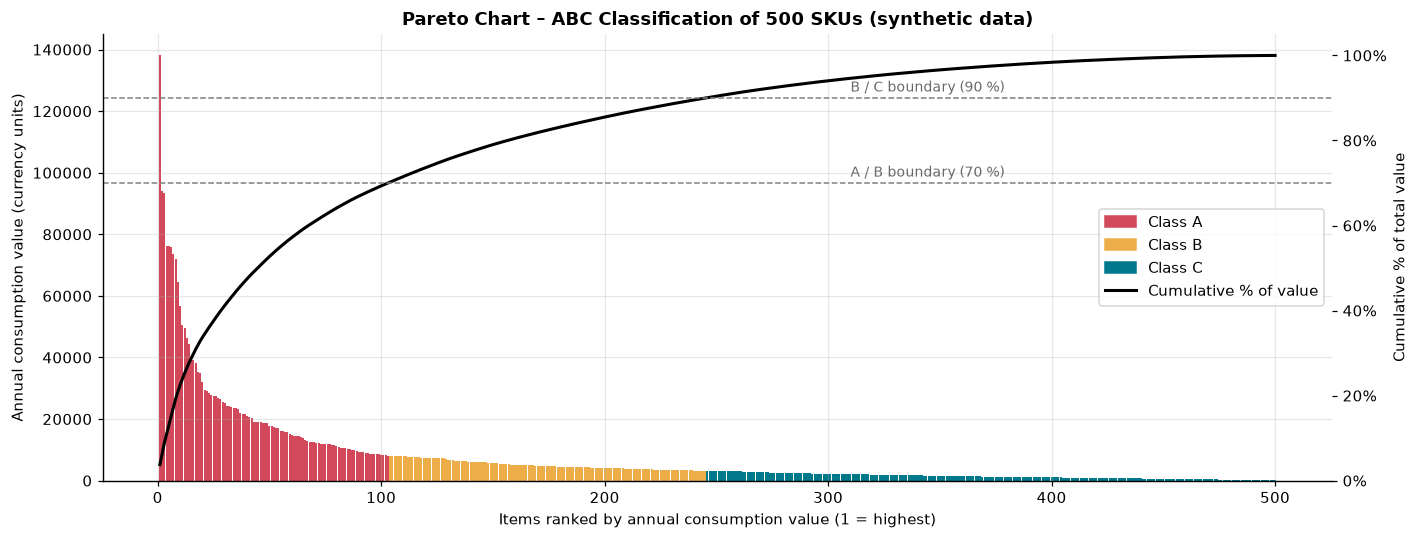

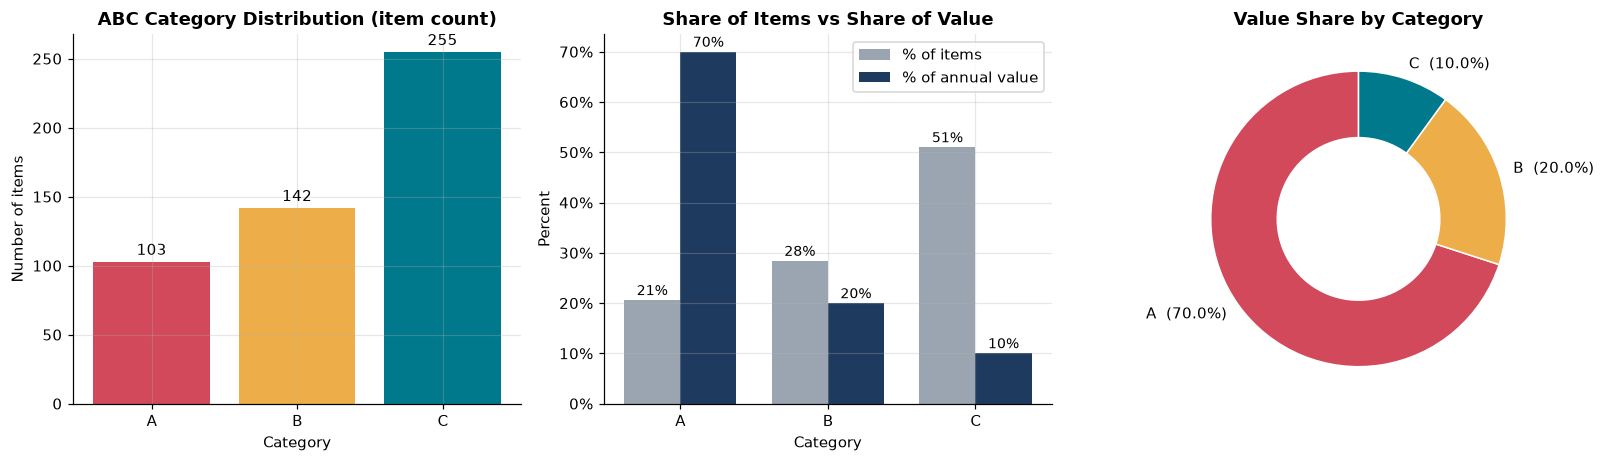

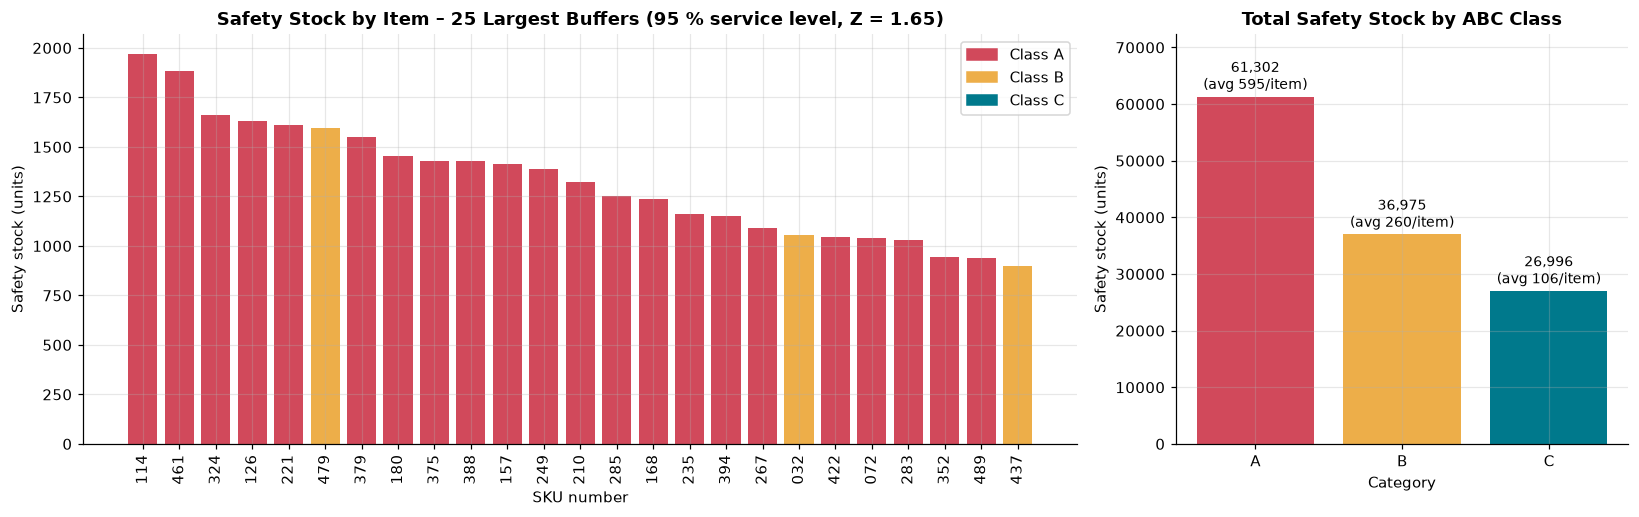

In [11]:
# ---- Figure 1: Pareto chart --------------------------------------------------
fig, ax1 = plt.subplots(figsize=(13, 5))
colors = df['ABC_Category'].map(PAL)
ax1.bar(range(1, len(df) + 1), df['Annual_Value'], color=colors, width=0.9)
ax1.set_xlabel('Items ranked by annual consumption value (1 = highest)')
ax1.set_ylabel('Annual consumption value (currency units)')
ax1.set_title('Pareto Chart – ABC Classification of 500 SKUs (synthetic data)')
ax2 = ax1.twinx()
ax2.plot(range(1, len(df) + 1), df['Cumulative%'], color='black', lw=2, label='Cumulative % of value')
ax2.axhline(70, color='gray', ls='--', lw=1); ax2.axhline(90, color='gray', ls='--', lw=1)
ax2.text(len(df) * 0.62, 71.5, 'A / B boundary (70 %)', fontsize=9, color='dimgray')
ax2.text(len(df) * 0.62, 91.5, 'B / C boundary (90 %)', fontsize=9, color='dimgray')
ax2.set_ylim(0, 105); ax2.set_ylabel('Cumulative % of total value'); ax2.yaxis.set_major_formatter(mtick.PercentFormatter())
ax2.grid(False)
from matplotlib.patches import Patch
handles = [Patch(color=PAL[c], label=f'Class {c}') for c in 'ABC'] + [plt.Line2D([0], [0], color='black', lw=2, label='Cumulative % of value')]
ax1.legend(handles=handles, loc='center right')
plt.tight_layout(); plt.savefig('outputs/A5_pareto_chart.png', dpi=150, bbox_inches='tight'); plt.show()

# ---- Figure 2: counts + value share -----------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
cnt = df['ABC_Category'].value_counts().reindex(list('ABC'))
bars = axes[0].bar(cnt.index, cnt.values, color=[PAL[c] for c in cnt.index])
axes[0].bar_label(bars, padding=2); axes[0].set_title('ABC Category Distribution (item count)')
axes[0].set_xlabel('Category'); axes[0].set_ylabel('Number of items')

x = np.arange(3); w = 0.38
axes[1].bar(x - w/2, abc['Items_%'], w, label='% of items', color='#9AA5B1')
axes[1].bar(x + w/2, abc['Value_%'], w, label='% of annual value', color='#1F3A5F')
for i, c in enumerate('ABC'):
    axes[1].text(i - w/2, abc.loc[c, 'Items_%'] + 1, f"{abc.loc[c, 'Items_%']:.0f}%", ha='center', fontsize=9)
    axes[1].text(i + w/2, abc.loc[c, 'Value_%'] + 1, f"{abc.loc[c, 'Value_%']:.0f}%", ha='center', fontsize=9)
axes[1].set_xticks(x); axes[1].set_xticklabels(list('ABC')); axes[1].legend()
axes[1].set_title('Share of Items vs Share of Value'); axes[1].set_xlabel('Category'); axes[1].set_ylabel('Percent')
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())

axes[2].pie(abc['Value_%'], labels=[f'{c}  ({v:.1f}%)' for c, v in zip('ABC', abc['Value_%'])],
            colors=[PAL[c] for c in 'ABC'], startangle=90, wedgeprops={'width': 0.45, 'edgecolor': 'white'})
axes[2].set_title('Value Share by Category'); axes[2].grid(False)
plt.tight_layout(); plt.savefig('outputs/A5_category_distribution.png', dpi=150, bbox_inches='tight'); plt.show()

# ---- Figure 3: safety stock by item and by class ----------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={'width_ratios': [2.2, 1]})
top = df.nlargest(25, 'Safety_Stock')
axes[0].bar(top['Item'].str.replace('SKU_', ''), top['Safety_Stock'], color=top['ABC_Category'].map(PAL))
axes[0].set_title('Safety Stock by Item – 25 Largest Buffers (95 % service level, Z = 1.65)')
axes[0].set_xlabel('SKU number'); axes[0].set_ylabel('Safety stock (units)')
axes[0].tick_params(axis='x', rotation=90)
axes[0].legend(handles=[Patch(color=PAL[c], label=f'Class {c}') for c in 'ABC'])

tot = ss_sum['Total_Safety_Stock']; avg = ss_sum['Avg_Safety_Stock']
b = axes[1].bar(list('ABC'), tot.values, color=[PAL[c] for c in 'ABC'])
axes[1].bar_label(b, labels=[f'{v:,.0f}\n(avg {a:,.0f}/item)' for v, a in zip(tot, avg)], padding=2, fontsize=9)
axes[1].set_title('Total Safety Stock by ABC Class'); axes[1].set_xlabel('Category'); axes[1].set_ylabel('Safety stock (units)')
axes[1].set_ylim(0, tot.max() * 1.18)
plt.tight_layout(); plt.savefig('outputs/A5_safety_stock_levels.png', dpi=150, bbox_inches='tight'); plt.show()

**Business interpretation – visuals.**
- **Pareto chart:** the cumulative curve rises steeply – the first ≈ 100 items (class A) already reach 70 % of value, while the long tail of class C (≈ 255 items) adds only the last 10 %. The bars shrink quickly, so the few tall red bars are the items worth the planner's time.
- **Counts and value share:** class C is the *largest by count* (≈ 51 %) but the *smallest by value* (≈ 10 %); class A is the opposite. The donut chart makes the "vital few, trivial many" message obvious.
- **Safety stock by item and class:** the 25 largest buffers are **22 class-A items and 3 class-B items (none from C)**, and the biggest single SKUs hold roughly 1,000–2,000 units each – these are the **inventory-risk hot-spots** to review first for lead-time reduction or supplier reliability. Class A holds 49 % of all buffer units, class C only 22 %, in line with the demand each class has to cover.

## A6. Learning Outcomes – AI vs Traditional, and What the Models Add
To make the three learning outcomes concrete, the next cell quantifies two things: **(i)** how much better the regression forecast is than the *traditional* static rule "next year = last year" (a naive forecast), and what that does to the buffer; **(ii)** how the trained decision tree classifies three **brand-new items** instantly, and how the forecast → safety-stock chain then treats them.

In [12]:
# (i) traditional naive forecast (last year's demand) vs regression forecast on the SAME test items
test_idx = yr_test.index
naive_mae = mean_absolute_error(yr_test, df.loc[test_idx, 'Past_Demand'])
naive_rmse = np.sqrt(mean_squared_error(yr_test, df.loc[test_idx, 'Past_Demand']))
cmp = pd.DataFrame({'MAE (units)': [naive_mae, mae_te], 'RMSE (units)': [naive_rmse, rmse_te]},
                   index=['Traditional: forecast = last year', 'AI/ML: linear regression'])
cmp['Error reduction vs traditional'] = [0.0, (1 - cmp.iloc[1, 0] / cmp.iloc[0, 0]) * 100]
display(cmp)
put('naive_mae', naive_mae); put('naive_rmse', naive_rmse)
put('mae_reduction_pct', (1 - mae_te / naive_mae) * 100)

# safety stock if the buffer used the naive forecast instead of the regression forecast
ss_naive = (Z_95 * (df['Past_Demand'] * 0.10) * np.sqrt(df['Lead_Time'])).round().sum()
print(f"Total safety stock with naive forecast : {ss_naive:,.0f} units")
print(f"Total safety stock with regression     : {df['Safety_Stock'].sum():,.0f} units")
put('ss_total_naive', ss_naive)

# (ii) classifying and buffering NEW items without the full cumulative-value table
new_items = pd.DataFrame({'Item': ['NEW_1', 'NEW_2', 'NEW_3'],
                          'Annual_Usage': [4200, 700, 90], 'Unit_Cost': [14.0, 5.0, 3.0],
                          'Lead_Time': [2, 4, 6], 'Past_Demand': [4000, 720, 85]})
new_items['Predicted_ABC'] = tree.predict(new_items[features])
new_items['Predicted_Demand'] = reg_all.predict(new_items[['Past_Demand']]).round()
new_items['Safety_Stock'] = (Z_95 * 0.10 * new_items['Predicted_Demand'] * np.sqrt(new_items['Lead_Time'])).round()
new_items['True_Annual_Value'] = new_items['Annual_Usage'] * new_items['Unit_Cost']
minA = df.loc[df['ABC_Category'] == 'A', 'Annual_Value'].min(); minB = df.loc[df['ABC_Category'] == 'B', 'Annual_Value'].min()
new_items['Class_by_value_rule'] = np.where(new_items['True_Annual_Value'] >= minA, 'A', np.where(new_items['True_Annual_Value'] >= minB, 'B', 'C'))
put('new_items_correct', int((new_items['Predicted_ABC'] == new_items['Class_by_value_rule']).sum()))
print("\nDecision-tree + regression applied to new items:")
display(new_items)

,MAE (units),RMSE (units),Error reduction vs traditional
Traditional: forecast = last year,61.75,105.71,0.00
AI/ML: linear regression,60.63,103.44,1.82


Total safety stock with naive forecast : 123,189 units
Total safety stock with regression     : 125,273 units

Decision-tree + regression applied to new items:


,Item,Annual_Usage,Unit_Cost,Lead_Time,Past_Demand,Predicted_ABC,Predicted_Demand,Safety_Stock,True_Annual_Value,Class_by_value_rule
0,NEW_1,4200,14.00,2,4000,A,"4,046.00",944.00,"58,800.00",A
1,NEW_2,700,5.00,4,720,C,733.00,242.00,"3,500.00",B
2,NEW_3,90,3.00,6,85,C,92.00,37.00,270.00,C


**Business interpretation – the three learning outcomes.**

**1. How AI enhances traditional inventory models.**
- Traditional practice computes ABC and safety stock **once, from last year's numbers**. Here ML adds (i) a *forecast* – regression replaces "next year = last year" and cuts forecast error slightly (MAE 60.6 vs 61.8 units, **1.8 % lower**) – and (ii) a *learned classifier* that labels items without recomputing the cumulative table.
- The honest takeaway is that **on this synthetic data the gain from regression is small** (past demand is already a very good predictor); the benefit would be larger with trend, seasonality or extra drivers (price, promotions). The forecast also changes the buffer: 125,273 units with the regression forecast vs 123,189 with the naive forecast (+1.7 %), because the model removes the downward bias of last year's demand.

**2. Classification and regression for operational decisions.**
- **Classification (decision tree):** decides *how much management attention* an item gets. For the three new items, the tree labelled NEW_1 as A and NEW_3 as C correctly; **NEW_2 (value 3,500) was labelled C but the value rule makes it B** – a borderline case, consistent with B being the hardest class. Result: 2 of 3 new items correct, which is exactly the kind of boundary item a planner should double-check.
- **Regression (linear model):** decides *how much to stock*. The forecast feeds directly into the safety-stock formula, e.g. NEW_1 gets a buffer of 944 units and NEW_3 only 37 units, which turns a model output into an order-policy parameter.

**3. Visualising and interpreting inventory risk buffers.**
- The Pareto chart shows *where value is concentrated*; the safety-stock bar charts show *where the buffer (risk protection) and the money are concentrated*. Reading them together: class A needs the best forecasts (an error there costs the most), class C can run on simple rules, and the large single-item buffers are the first candidates for lead-time or variability reduction.

---
## A7. Before AI vs After AI – Comparison of Plots *(requested by the professor)*
The professor asked for the plots **before AI** (the traditional way of working) next to the plots **after AI** (the models built in A2–A4). Three comparisons follow, each on the **same items** so that the comparison is fair:

| Decision | **Before AI (traditional)** | **After AI** |
|---|---|---|
| **Classification** | Single-criterion rule of thumb: rank items by *annual usage only* and call the top 20 % "A", next 30 % "B", rest "C" (it ignores unit cost) | Decision tree using usage, **cost**, lead time and past demand (A2) |
| **Demand forecast** | Naive rule: next year's demand = last year's demand | Linear regression (A3) |
| **Safety stock** | One flat rule: buffer = a fixed % of last year's demand, the same % for every item, lead time ignored (the % is set so that the **total number of buffer units is identical** to the AI buffer – same budget) | Z · σ · √LT on the predicted demand (A4) |

*Reference for what to expect:* the literature describes ML for ABC mainly as a way to **replicate and extend** multi-criteria classification so new items can be classified without re-running the full analysis (e.g. Lolli et al., decision trees for supervised multi-criteria inventory classification), and vendor/consulting sources claim large forecast-error reductions from AI forecasting (often quoted as 20–50 %). I do **not** assume those figures: everything below is measured on my synthetic data and the gains are reported as they come out.

#### A7.1 Classification – traditional rule of thumb vs decision tree
Both are scored against the true value-based ABC class on the **same 150 test items**.

,Before AI (usage-only rule),After AI (decision tree),Change (pp)
Accuracy,0.65,0.91,26.00
Macro-F1,0.61,0.89,27.56
Recall of class A,0.58,0.87,29.03


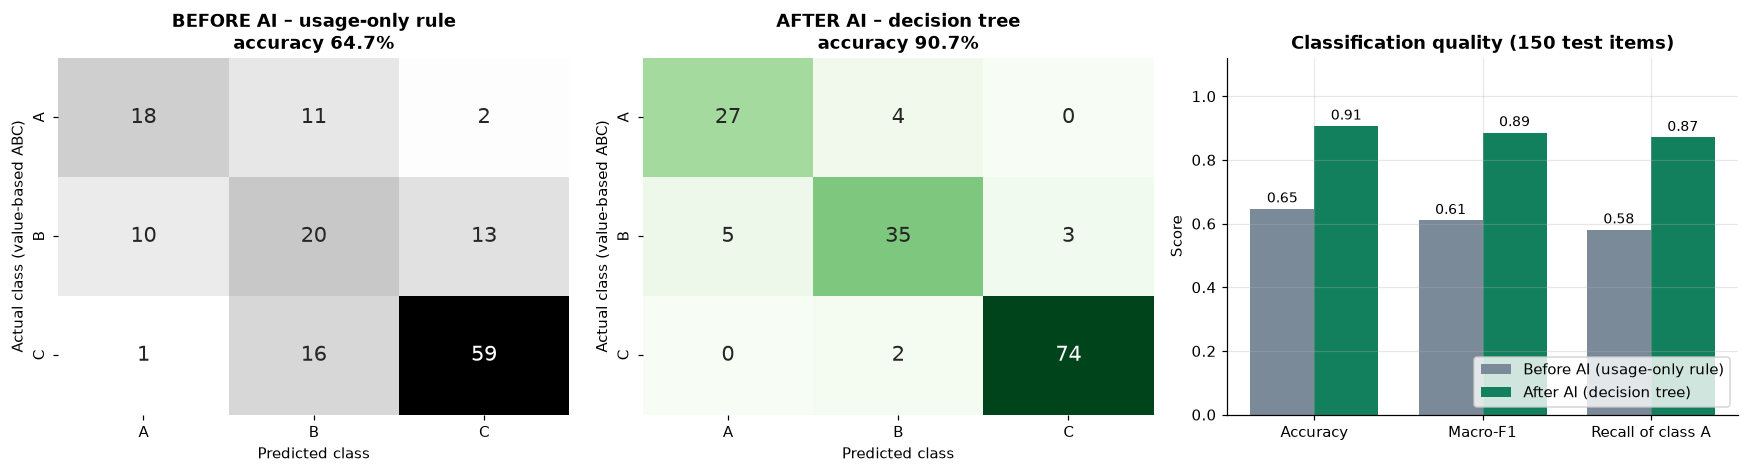

In [13]:
# ---- BEFORE: single-criterion rule of thumb (rank by annual usage only) ----------------
usage_share = df['Annual_Usage'].rank(ascending=False, method='first') / len(df)
df['Traditional_ABC'] = np.where(usage_share <= 0.20, 'A', np.where(usage_share <= 0.50, 'B', 'C'))
trad_test = df.loc[X_test.index, 'Traditional_ABC']

cm_trad = confusion_matrix(y_test, trad_test, labels=labels)
acc_trad = accuracy_score(y_test, trad_test)
rep_trad = classification_report(y_test, trad_test, labels=labels, output_dict=True)
recallA_trad = cm_trad[0, 0] / cm_trad[0].sum(); recallA_ai = cm[0, 0] / cm[0].sum()

cls_cmp = pd.DataFrame({'Before AI (usage-only rule)': [acc_trad, rep_trad['macro avg']['f1-score'], recallA_trad],
                        'After AI (decision tree)':   [acc_test, rep['macro avg']['f1-score'], recallA_ai]},
                       index=['Accuracy', 'Macro-F1', 'Recall of class A'])
cls_cmp['Change (pp)'] = (cls_cmp.iloc[:, 1] - cls_cmp.iloc[:, 0]) * 100
display(cls_cmp.round(3))
for k, v in {'ba_cls_acc_before': acc_trad, 'ba_cls_acc_after': acc_test, 'ba_cls_f1_before': rep_trad['macro avg']['f1-score'],
             'ba_cls_f1_after': rep['macro avg']['f1-score'], 'ba_cls_recallA_before': recallA_trad,
             'ba_cls_recallA_after': recallA_ai}.items():
    put(k, v)
put('ba_cls_a_missed_before', int(cm_trad[0].sum() - cm_trad[0, 0])); put('ba_cls_a_missed_after', int(cm[0].sum() - cm[0, 0]))
put('ba_cls_a_total', int(cm[0].sum()))

GREY, GRN = '#7A8A99', '#12805C'
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
sns.heatmap(cm_trad, annot=True, fmt='d', cmap='Greys', xticklabels=labels, yticklabels=labels, cbar=False, ax=axes[0], annot_kws={'size': 14})
axes[0].set_title(f'BEFORE AI – usage-only rule\naccuracy {acc_trad:.1%}'); axes[0].set_xlabel('Predicted class'); axes[0].set_ylabel('Actual class (value-based ABC)'); axes[0].grid(False)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=labels, yticklabels=labels, cbar=False, ax=axes[1], annot_kws={'size': 14})
axes[1].set_title(f'AFTER AI – decision tree\naccuracy {acc_test:.1%}'); axes[1].set_xlabel('Predicted class'); axes[1].set_ylabel('Actual class (value-based ABC)'); axes[1].grid(False)
x = np.arange(3); w = 0.38
b1 = axes[2].bar(x - w/2, cls_cmp.iloc[:, 0], w, color=GREY, label='Before AI (usage-only rule)')
b2 = axes[2].bar(x + w/2, cls_cmp.iloc[:, 1], w, color=GRN, label='After AI (decision tree)')
axes[2].bar_label(b1, fmt='%.2f', padding=2, fontsize=9); axes[2].bar_label(b2, fmt='%.2f', padding=2, fontsize=9)
axes[2].set_xticks(x); axes[2].set_xticklabels(cls_cmp.index); axes[2].set_ylim(0, 1.12); axes[2].legend(loc='lower right')
axes[2].set_title('Classification quality (150 test items)'); axes[2].set_ylabel('Score')
plt.tight_layout(); plt.savefig('outputs/A7_before_after_classification.png', dpi=150, bbox_inches='tight'); plt.show()

**Business interpretation – classification, before vs after AI.**
- Judged against the true value-based ABC class on the same 150 test items, the usage-only rule of thumb is right for **64.7 %** of the items; the decision tree is right for **90.7 %** (**+26.0 percentage points**). Macro-F1 rises from 0.61 to 0.89.
- **The costly mistake is missing class-A items.** The rule flags only **18 of 31** A items (recall 58%); 11 of the missed ones are called B and 2 are called C. The tree finds **27 of 31** (recall 87%) and none is called C.
- Why: the rule looks at volume only, so a cheap high-volume item looks like A and an expensive moderate-volume item is overlooked. The tree learns that **unit cost is the most important feature** (A2) and picks up the thresholds from data.
- *Fair reading:* this compares AI with a quick rule of thumb. The exact value-based ABC (A1) is perfectly accurate by definition but needs the whole cumulative table to be recomputed; the tree's practical value is labelling *new or changed* items instantly, with the borderline B items still deserving a manual check.

#### A7.2 Demand forecast – naive "same as last year" vs linear regression

,Before AI (naive: last year),After AI (linear regression),Change
MAE (units),61.75,60.63,-1.13
RMSE (units),105.71,103.44,-2.27
Bias (mean actual - forecast),26.19,16.81,-9.38
MAPE (%),6.48,7.03,0.55
R2,0.99,0.99,0.00


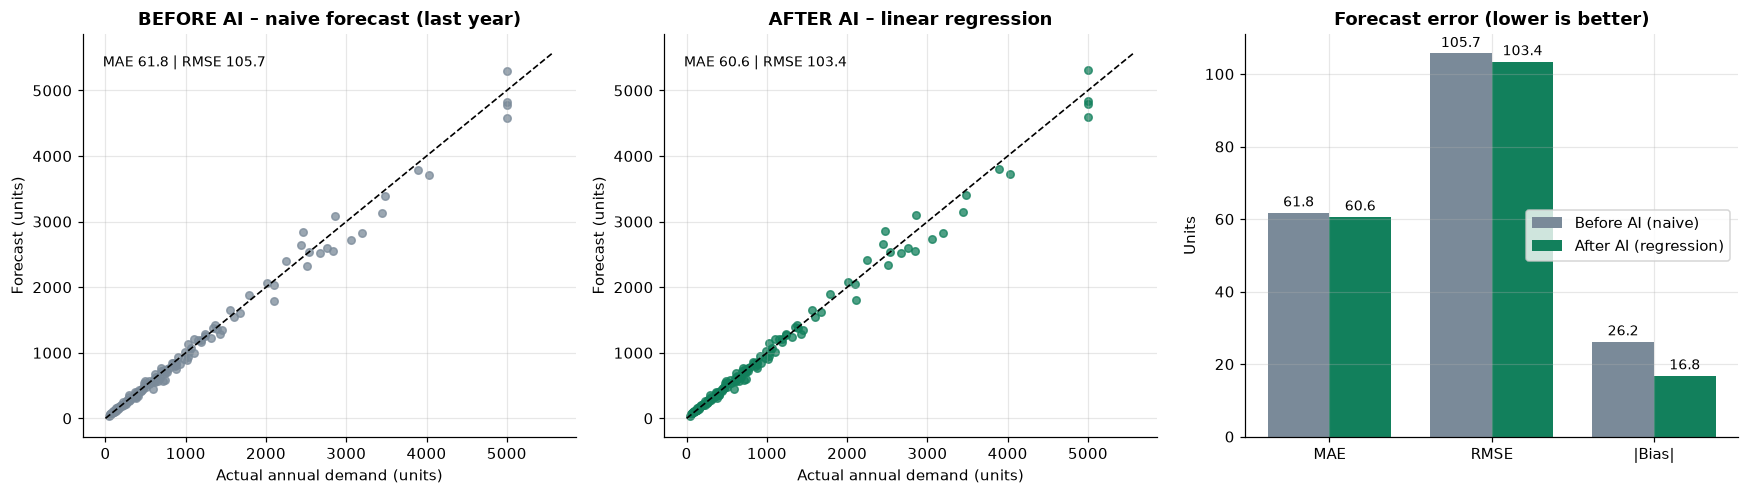

In [14]:
actual_t = yr_test
naive_t = df.loc[yr_test.index, 'Past_Demand']
ai_t = pd.Series(yr_pred, index=yr_test.index)

def fc_metrics(a, p):
    e = a - p
    return {'MAE (units)': mean_absolute_error(a, p), 'RMSE (units)': np.sqrt(mean_squared_error(a, p)),
            'Bias (mean actual - forecast)': e.mean(), 'MAPE (%)': (e.abs() / a).mean() * 100, 'R2': r2_score(a, p)}
fc_cmp = pd.DataFrame({'Before AI (naive: last year)': fc_metrics(actual_t, naive_t),
                       'After AI (linear regression)': fc_metrics(actual_t, ai_t)})
fc_cmp['Change'] = fc_cmp.iloc[:, 1] - fc_cmp.iloc[:, 0]
display(fc_cmp.round(3))
for i, nm in enumerate(['mae', 'rmse', 'bias', 'mape', 'r2']):
    put(f'ba_fc_{nm}_before', fc_cmp.iloc[i, 0]); put(f'ba_fc_{nm}_after', fc_cmp.iloc[i, 1])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
lim = [0, max(actual_t.max(), naive_t.max(), ai_t.max()) * 1.05]
for ax, pred, ttl, col in [(axes[0], naive_t, 'BEFORE AI – naive forecast (last year)', GREY), (axes[1], ai_t, 'AFTER AI – linear regression', GRN)]:
    ax.scatter(actual_t, pred, s=24, alpha=0.75, color=col); ax.plot(lim, lim, 'k--', lw=1.1)
    ax.set_title(ttl); ax.set_xlabel('Actual annual demand (units)'); ax.set_ylabel('Forecast (units)')
    ax.text(0.04, 0.92, f"MAE {mean_absolute_error(actual_t, pred):.1f} | RMSE {np.sqrt(mean_squared_error(actual_t, pred)):.1f}", transform=ax.transAxes, fontsize=9)
x = np.arange(3); w = 0.38
vals_b = [fc_cmp.iloc[0, 0], fc_cmp.iloc[1, 0], abs(fc_cmp.iloc[2, 0])]; vals_a = [fc_cmp.iloc[0, 1], fc_cmp.iloc[1, 1], abs(fc_cmp.iloc[2, 1])]
b1 = axes[2].bar(x - w/2, vals_b, w, color=GREY, label='Before AI (naive)'); b2 = axes[2].bar(x + w/2, vals_a, w, color=GRN, label='After AI (regression)')
axes[2].bar_label(b1, fmt='%.1f', padding=2, fontsize=9); axes[2].bar_label(b2, fmt='%.1f', padding=2, fontsize=9)
axes[2].set_xticks(x); axes[2].set_xticklabels(['MAE', 'RMSE', '|Bias|']); axes[2].set_ylabel('Units'); axes[2].legend()
axes[2].set_title('Forecast error (lower is better)')
plt.tight_layout(); plt.savefig('outputs/A7_before_after_forecast.png', dpi=150, bbox_inches='tight'); plt.show()

**Business interpretation – forecast, before vs after AI.**
- **The gain is small.** Test MAE falls from 61.8 to **60.6 units** (1.8 % lower) and RMSE from 105.7 to 103.4 (2.1 % lower). R² is 0.990 vs 0.991.
- **What the regression does fix is the systematic bias:** the naive forecast under-forecasts by 26.2 units per item on average (last year's demand was about 2 % lower than this year's in the data), the regression by 16.8 – roughly **36 % less bias**. In percentage terms the picture is mixed: MAPE is 6.48 % for the naive forecast and 7.03 % for the regression, i.e. slightly *worse*, because the regression trades a little accuracy on small items for less bias on large ones.
- **Honest conclusion:** the two scatter plots look almost the same. On this synthetic data last year's demand is already an excellent predictor, so a one-variable regression cannot add much. Claims in the literature of 20–50 % lower forecast error come from richer models and real data with trend, seasonality and promotions; **they are not reproduced here**.

#### A7.3 Safety stock – one flat rule vs Z · σ · √LT on the predicted demand
Same budget: the flat rule's % is set so that it holds exactly as many buffer units in total as the AI approach. To judge the *protection* each buffer gives, I use the same risk model as in A4 (σ = 10 % of predicted demand, lead time √LT) and compute the **achieved service level** of every item as Φ(buffer ÷ (σ·√LT)). *(This evaluates both rules with my assumed σ model, so it measures consistency of protection, not real-world stock-outs.)*

Flat rule: buffer = 29.8% of last year's demand for every item (lead time ignored)


,Before AI (flat % of last year),After AI (Z x sigma x sqrt(LT))
Total buffer (units),"125,273.00","125,273.00"
Buffer value (units x cost),"1,065,506.43","1,068,539.89"
Mean achieved service level,0.95,0.95
Lowest item service level,0.84,0.94
Items below 90 % service,55.00,0.00
Items below 80 % service,0.00,0.00
Std. dev. of item service level (pp),3.58,0.10


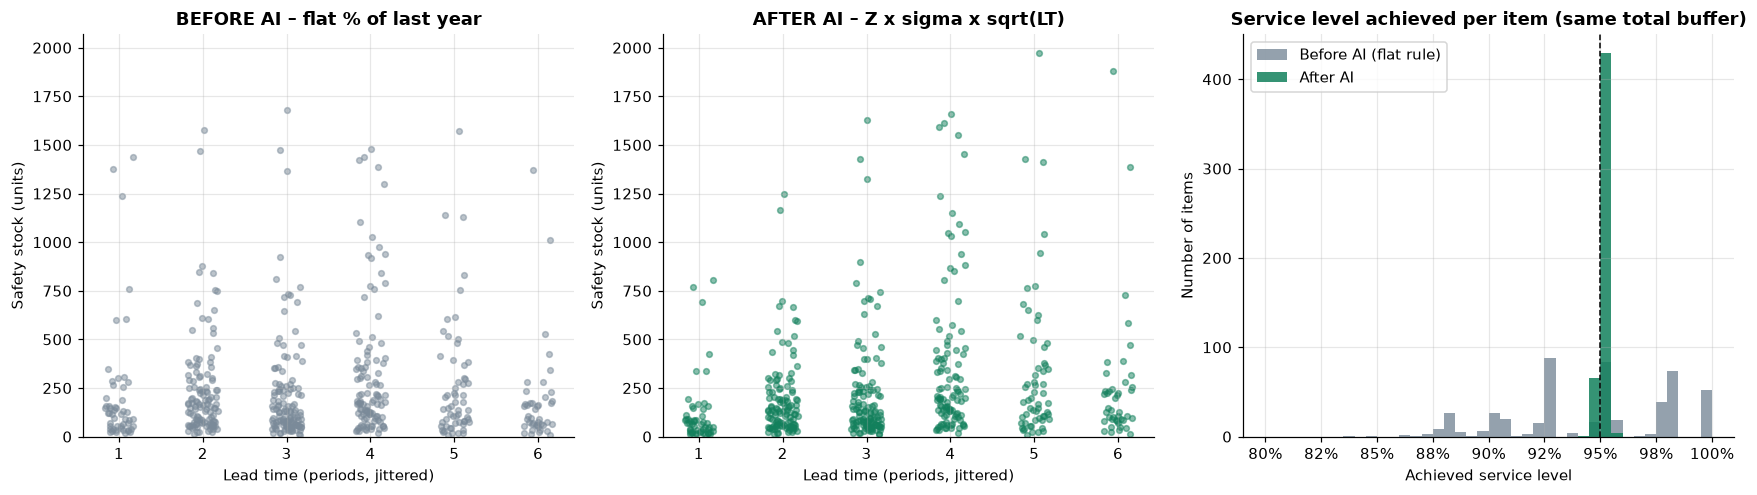

In [15]:
flat_pct = df['Safety_Stock'].sum() / df['Past_Demand'].sum()            # same total units as the AI buffer
df['SS_Before'] = flat_pct * df['Past_Demand']
df['SS_After'] = df['Safety_Stock']
sigma_lt = df['Std_Dev'] * np.sqrt(df['Lead_Time'])                       # risk model of A4
df['CSL_Before'] = norm.cdf(df['SS_Before'] / sigma_lt)
df['CSL_After'] = norm.cdf(df['SS_After'] / sigma_lt)

sc = pd.DataFrame({
    'Total buffer (units)': [df['SS_Before'].sum(), df['SS_After'].sum()],
    'Buffer value (units x cost)': [(df['SS_Before'] * df['Unit_Cost']).sum(), (df['SS_After'] * df['Unit_Cost']).sum()],
    'Mean achieved service level': [df['CSL_Before'].mean(), df['CSL_After'].mean()],
    'Lowest item service level': [df['CSL_Before'].min(), df['CSL_After'].min()],
    'Items below 90 % service': [(df['CSL_Before'] < 0.90).sum(), (df['CSL_After'] < 0.90).sum()],
    'Items below 80 % service': [(df['CSL_Before'] < 0.80).sum(), (df['CSL_After'] < 0.80).sum()],
    'Std. dev. of item service level (pp)': [df['CSL_Before'].std() * 100, df['CSL_After'].std() * 100],
}, index=['Before AI (flat % of last year)', 'After AI (Z x sigma x sqrt(LT))']).T
print(f"Flat rule: buffer = {flat_pct:.1%} of last year's demand for every item (lead time ignored)")
display(sc)
for i, nm in enumerate(['units', 'value', 'csl_mean', 'csl_min', 'below90', 'below80', 'csl_sd']):
    put(f'ba_ss_{nm}_before', sc.iloc[i, 0]); put(f'ba_ss_{nm}_after', sc.iloc[i, 1])
put('ba_ss_flat_pct', flat_pct * 100)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
axes[0].scatter(df['Lead_Time'] + np.random.default_rng(1).uniform(-0.18, 0.18, len(df)), df['SS_Before'], s=14, alpha=0.5, color=GREY)
axes[0].set_title('BEFORE AI – flat % of last year'); axes[0].set_xlabel('Lead time (periods, jittered)'); axes[0].set_ylabel('Safety stock (units)')
axes[1].scatter(df['Lead_Time'] + np.random.default_rng(1).uniform(-0.18, 0.18, len(df)), df['SS_After'], s=14, alpha=0.5, color=GRN)
axes[1].set_title('AFTER AI – Z x sigma x sqrt(LT)'); axes[1].set_xlabel('Lead time (periods, jittered)'); axes[1].set_ylabel('Safety stock (units)')
ymax_ss = max(df['SS_Before'].max(), df['SS_After'].max()) * 1.05
axes[0].set_ylim(0, ymax_ss); axes[1].set_ylim(0, ymax_ss)
bins = np.linspace(0.80, 1.0, 41)
axes[2].hist(df['CSL_Before'], bins=bins, color=GREY, alpha=0.8, label='Before AI (flat rule)')
axes[2].hist(df['CSL_After'], bins=bins, color=GRN, alpha=0.85, label='After AI')
axes[2].axvline(0.95, color='k', ls='--', lw=1); axes[2].xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=0))
axes[2].set_title('Service level achieved per item (same total buffer)'); axes[2].set_xlabel('Achieved service level'); axes[2].set_ylabel('Number of items'); axes[2].legend(loc='upper left')
plt.tight_layout(); plt.savefig('outputs/A7_before_after_safety_stock.png', dpi=150, bbox_inches='tight'); plt.show()

**Business interpretation – safety stock, before vs after AI (same total budget).**
- Both approaches hold exactly **125,273 units** of buffer (worth ≈ 1,065,506 vs 1,068,540 at unit cost). The flat rule uses 29.8 % of last year's demand for every item.
- **What changes is how the protection is spread.** The flat rule ignores lead time, so the left plot shows no relation between buffer and lead time. Under the same risk model, it gives **55 items less than 90 % service** (the worst item only 83.7 %) while others get close to 100 %. The Z · σ · √LT buffer gives every item ≈ 95 %: **no item below 90 %**, worst item 94.4 %, spread between items 3.58 → 0.10 percentage points.
- In business terms: with the same inventory investment, the AI-based rule moves units from short-lead-time, low-risk items to long-lead-time, high-risk items, so nothing is left dangerously unprotected.
- *Limit of this test:* both rules are evaluated with my assumed σ model (10 % of predicted demand), so it shows consistency of protection, not measured stock-outs.

#### A7.4 Part A scorecard – before vs after AI

In [16]:
score = pd.DataFrame({
    'Metric': ['Classification accuracy (test)', 'Class-A items correctly flagged', 'Forecast MAE (units)', 'Forecast RMSE (units)',
               'Forecast bias (units)', 'Items below 90 % service', 'Lowest item service level'],
    'Before AI': [f"{acc_trad:.1%}", f"{cm_trad[0,0]} of {cm_trad[0].sum()}", f"{fc_cmp.iloc[0,0]:.1f}", f"{fc_cmp.iloc[1,0]:.1f}",
                  f"{fc_cmp.iloc[2,0]:+.1f}", f"{int(sc.iloc[4,0])}", f"{sc.iloc[3,0]:.1%}"],
    'After AI':  [f"{acc_test:.1%}", f"{cm[0,0]} of {cm[0].sum()}", f"{fc_cmp.iloc[0,1]:.1f}", f"{fc_cmp.iloc[1,1]:.1f}",
                  f"{fc_cmp.iloc[2,1]:+.1f}", f"{int(sc.iloc[4,1])}", f"{sc.iloc[3,1]:.1%}"]}).set_index('Metric')
display(score)

,Before AI,After AI
Metric,,
Classification accuracy (test),64.7%,90.7%
Class-A items correctly flagged,18 of 31,27 of 31
Forecast MAE (units),61.8,60.6
Forecast RMSE (units),105.7,103.4
Forecast bias (units),+26.2,+16.8
Items below 90 % service,55,0
Lowest item service level,83.7%,94.4%


**Business interpretation – Part A scorecard.** Before → after AI on the same items:
- **Classification:** 64.7 % → **90.7 %** accuracy; class-A items found 18 → **27** of 31. *Clear gain.*
- **Forecast:** MAE 61.8 → 60.6, bias +26.2 → +16.8. *Marginal gain – honest result on this data.*
- **Safety stock (same budget):** items below 90 % service 55 → **0**; lowest item 83.7 % → **94.4 %**. *Clear gain in risk consistency.*

The pattern is typical: AI adds the most where the traditional method **ignores information** (cost in the classification, lead time in the buffer) and the least where the traditional method is already close to the best possible (a near-perfect last-year forecast).

---
# PART B – LAB EXERCISE: Advanced Service-Level Trade-Off Simulation (Multi-Product Inventory Strategy)

**Scenario (slide 32):** a supply-chain manager oversees three products with different demand patterns and cost structures and must choose a service level for each by balancing **customer satisfaction** (service level), **inventory risk** (safety stock) and **financial impact** (holding cost).

## B1. Product Parameters
Products A, B and C each get their own demand, variability, lead time and holding cost per unit. These values are **my assumptions** (see Section 4) calibrated to reproduce the scale of the reference chart. Product **A** is a high-volume, stable item; **B** is a medium-volume item with *highly variable* demand and a long lead time; **C** is a low-volume item with a short lead time but the *highest* holding cost per unit.

In [17]:
products = pd.DataFrame({
    'Product':      ['A', 'B', 'C'],
    'Avg_Demand':   [400, 250, 150],     # units per period (week)
    'Demand_Std':   [30, 50, 20],        # sigma, units per period
    'Lead_Time':    [3, 4, 2],           # periods
    'Holding_Cost': [2.00, 1.50, 2.50],  # currency per unit per period
}).set_index('Product')
products['CV_%'] = products['Demand_Std'] / products['Avg_Demand'] * 100          # demand variability
products['Sigma_x_sqrtLT'] = products['Demand_Std'] * np.sqrt(products['Lead_Time'])   # std of lead-time demand

print("B1 – Parameter table (assumed values; units per period = week):")
display(products)
for p in products.index:
    put(f'B_cv_{p}', products.loc[p, 'CV_%']); put(f'B_sig_lt_{p}', products.loc[p, 'Sigma_x_sqrtLT'])

B1 – Parameter table (assumed values; units per period = week):


,Avg_Demand,Demand_Std,Lead_Time,Holding_Cost,CV_%,Sigma_x_sqrtLT
Product,,,,,,
A,400,30,3,2.00,7.50,51.96
B,250,50,4,1.50,20.00,100.00
C,150,20,2,2.50,13.33,28.28


**Business interpretation – parameters.** The three products are deliberately different:
- **A** – high volume (400/period), *stable* demand (CV = 7.5 %), lead time 3, holding cost 2.00.
- **B** – medium volume (250/period) but *highly volatile* demand (CV = 20.0 %) and the *longest* lead time (4), cheapest to hold (1.50).
- **C** – low volume (150/period), moderate variability (CV = 13.3 %), *shortest* lead time (2) but the *most expensive* to hold (2.50).

The column σ·√L (std. deviation of demand over the lead time) is what really scales the buffer: B (100.0) is about **1.9×** A (52.0) and **3.5×** C (28.3). So B will need the biggest buffers even though its average demand is not the highest.

## B2 & B3. Service Levels (80 % → 99 %) and Matching Z-Scores
Service levels are simulated on a grid from 80 % to 99 % in 1-percentage-point steps (20 points). Each service level is converted into a Z-score with the inverse standard-normal CDF, `scipy.stats.norm.ppf` – no hard-coded values in Part B.

In [18]:
service_levels = np.round(np.linspace(0.80, 0.99, 20), 2)       # 80%, 81%, ... 99%
z_scores = norm.ppf(service_levels)                                # B3: Z matched to each service level
z_tbl = pd.DataFrame({'Service Level': [f'{s:.0%}' for s in service_levels], 'Z-score': z_scores})
print(f"{len(service_levels)} service levels from {service_levels[0]:.0%} to {service_levels[-1]:.0%}")
display(z_tbl.T)
for s in (0.80, 0.90, 0.95, 0.99):
    put(f'Z_{int(s*100)}', norm.ppf(s))

20 service levels from 80% to 99%


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
Service Level,80%,81%,82%,83%,84%,85%,86%,87%,88%,89%,90%,91%,92%,93%,94%,95%,96%,97%,98%,99%
Z-score,0.84,0.88,0.92,0.95,0.99,1.04,1.08,1.13,1.17,1.23,1.28,1.34,1.41,1.48,1.55,1.64,1.75,1.88,2.05,2.33


**Business interpretation – Z-scores.** The Z-score rises slowly at first and sharply at the top end: 80 % → 0.84, 90 % → 1.28, 95 % → 1.64 (≈ the 1.65 used in Part A), 99 % → 2.33. Going from 80 % to 90 % (+10 points) adds 0.44 to Z, whereas going from 90 % to 99 % (+9 points) adds 1.04 – more than twice as much. The tail of the normal curve is what makes the last points of service so expensive.

## B4. Safety Stock and Holding Cost
For every product *p* and service level *s*:

$$\text{Safety Stock}_{p,s} = Z_s \times \sigma_p \times \sqrt{\text{Lead Time}_p}\qquad\qquad \text{Holding Cost}_{p,s} = \text{Safety Stock}_{p,s} \times h_p$$

In [19]:
records = []
for p, r in products.iterrows():
    ss = z_scores * r['Demand_Std'] * np.sqrt(r['Lead_Time'])      # safety stock (units)
    hc = ss * r['Holding_Cost']                                      # holding cost per period
    for s, z, a, b in zip(service_levels, z_scores, ss, hc):
        records.append({'Product': p, 'Service_Level': s, 'Z': z, 'Safety_Stock': a, 'Holding_Cost': b})
sim = pd.DataFrame(records)

print("Safety stock (units) – every service level:")
display(sim.pivot(index='Service_Level', columns='Product', values='Safety_Stock').round(1).T)
print("Holding cost (currency per period) – every service level:")
display(sim.pivot(index='Service_Level', columns='Product', values='Holding_Cost').round(1).T)

Safety stock (units) – every service level:


Service_Level,0.80,0.81,0.82,0.83,0.84,0.85,0.86,0.87,0.88,0.89,0.90,0.91,0.92,0.93,0.94,0.95,0.96,0.97,0.98,0.99
Product,,,,,,,,,,,,,,,,,,,,
A,43.70,45.60,47.60,49.60,51.70,53.90,56.10,58.50,61.10,63.70,66.60,69.70,73.00,76.70,80.80,85.50,91.00,97.70,106.70,120.90
B,84.20,87.80,91.50,95.40,99.40,103.60,108.00,112.60,117.50,122.70,128.20,134.10,140.50,147.60,155.50,164.50,175.10,188.10,205.40,232.60
C,23.80,24.80,25.90,27.00,28.10,29.30,30.60,31.90,33.20,34.70,36.20,37.90,39.70,41.70,44.00,46.50,49.50,53.20,58.10,65.80


Holding cost (currency per period) – every service level:


Service_Level,0.80,0.81,0.82,0.83,0.84,0.85,0.86,0.87,0.88,0.89,0.90,0.91,0.92,0.93,0.94,0.95,0.96,0.97,0.98,0.99
Product,,,,,,,,,,,,,,,,,,,,
A,87.50,91.20,95.10,99.20,103.30,107.70,112.30,117.10,122.10,127.50,133.20,139.30,146.00,153.40,161.60,170.90,181.90,195.50,213.40,241.80
B,126.20,131.70,137.30,143.10,149.20,155.50,162.00,169.00,176.20,184.00,192.20,201.10,210.80,221.40,233.20,246.70,262.60,282.10,308.10,349.00
C,59.50,62.10,64.70,67.50,70.30,73.30,76.40,79.60,83.10,86.70,90.60,94.80,99.40,104.40,109.90,116.30,123.80,133.00,145.20,164.50


#### B4 (continued) – Monte-Carlo check of the simulated service levels
The formulas assume normally distributed lead-time demand. To verify that the safety stock really delivers the intended service level, I simulate **200,000 lead-time demands** per product, N(μ·L, σ·√L), set the reorder point to *mean + safety stock*, and measure the share of cycles without a stock-out (achieved cycle service level).

In [20]:
rng = np.random.default_rng(SEED)
n_sim = 200_000
mc_rows = []
for p, r in products.iterrows():
    mu_lt = r['Avg_Demand'] * r['Lead_Time']
    sd_lt = r['Demand_Std'] * np.sqrt(r['Lead_Time'])
    ltd = rng.normal(mu_lt, sd_lt, n_sim)                           # simulated lead-time demand
    for s in service_levels:
        ss = norm.ppf(s) * sd_lt
        mc_rows.append({'Product': p, 'Target': s, 'Achieved': (ltd <= mu_lt + ss).mean()})
mc = pd.DataFrame(mc_rows)
mc['Abs_Error_pp'] = (mc['Achieved'] - mc['Target']).abs() * 100
print("Achieved vs target service level (selected levels):")
display(mc[mc['Target'].isin([0.80, 0.90, 0.95, 0.99])].assign(
    Target=lambda t: (t['Target'] * 100).round(0).astype(int).astype(str) + '%',
    Achieved=lambda t: t['Achieved'].map('{:.2%}'.format)).pivot(index='Product', columns='Target', values='Achieved'))
print(f"Maximum absolute deviation over all products and levels: {mc['Abs_Error_pp'].max():.2f} percentage points")
put('mc_max_err_pp', mc['Abs_Error_pp'].max())

Achieved vs target service level (selected levels):


Target,80%,90%,95%,99%
Product,,,,
A,79.97%,89.94%,94.95%,98.96%
B,80.00%,90.00%,95.02%,99.00%
C,80.05%,90.12%,95.04%,99.02%


Maximum absolute deviation over all products and levels: 0.15 percentage points


**Business interpretation – safety stock and holding cost, and simulation check.**
- At every service level Product **B** needs the largest buffer and Product **C** the smallest (e.g. at 95 %: B 164.5, A 85.5, C 46.5 units), in line with the σ·√L ranking.
- Holding cost = safety stock × cost per unit. C has the highest unit holding cost (2.50) but still the lowest *total* holding cost because its buffer is small.
- **Monte-Carlo check:** simulating 200,000 lead-time demands per product, the achieved service levels match the targets within **0.15 percentage points** (sampling noise), so the Z-based formula really delivers the intended probability of not stocking out – *under the normal-demand assumption*.

## B5. Service-Level Trade-off Figure (one figure, three side-by-side subplots)
Products A | B | C, x-axis = service level 80–99 %, y-axis = Units / Cost, **blue = Safety Stock (units)**, **green = Holding Cost (currency per period)**, a legend in every subplot and a **shared y-axis** so the products can be compared directly – as in the reference chart on slide 33.

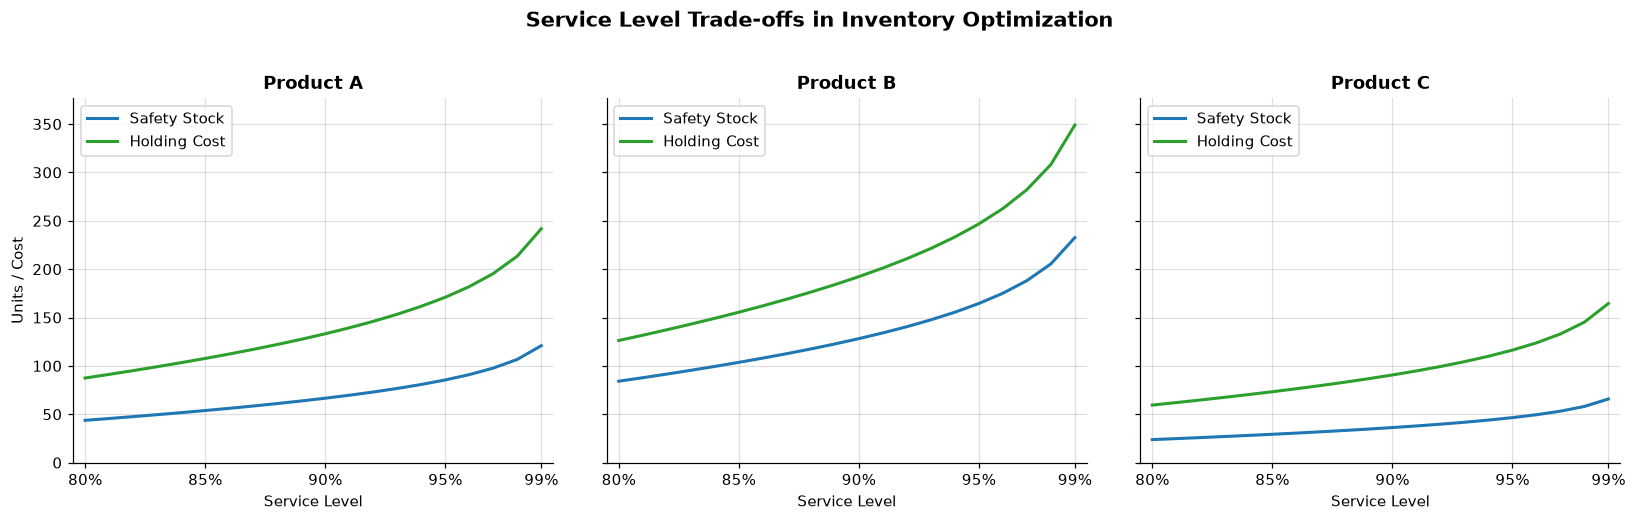

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for ax, p in zip(axes, products.index):
    d = sim[sim['Product'] == p]
    ax.plot(d['Service_Level'], d['Safety_Stock'], color=BLUE, lw=2, label='Safety Stock')
    ax.plot(d['Service_Level'], d['Holding_Cost'], color=GREEN, lw=2, label='Holding Cost')
    ax.set_title(f'Product {p}')
    ax.set_xlabel('Service Level')
    ax.set_xlim(0.795, 0.995)
    ax.set_xticks([0.80, 0.85, 0.90, 0.95, 0.99])
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=0))
    ax.grid(True, alpha=0.4)
    ax.legend(loc='upper left')
axes[0].set_ylabel('Units / Cost')
ymax = sim[['Safety_Stock', 'Holding_Cost']].to_numpy().max()
axes[0].set_ylim(0, ymax * 1.08)                      # sharey=True -> identical y-scale in all subplots
fig.suptitle('Service Level Trade-offs in Inventory Optimization', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout(w_pad=2.5)
plt.savefig('outputs/B5_service_level_tradeoffs.png', dpi=150, bbox_inches='tight')
plt.show()

**Business interpretation – the trade-off figure.**
- **Blue (safety stock) and green (holding cost) both rise with service level, and they rise non-linearly:** the curves are gentle between 80 % and 90 % and bend steeply above ≈ 95 %.
- **Same y-scale in all three panels** makes the comparison direct: Product **B** reaches ≈ 349 in holding cost at 99 %, A ≈ 242 and C ≈ 164; B's curves are the highest and C's the flattest.
- Green is above blue in every panel because holding cost = safety stock × cost per unit and every unit cost is above 1; the green-to-blue ratio is exactly the unit holding cost (C: 2.5×, A: 2.0×, B: 1.5×), so the two lines are parallel in shape and differ only by that factor.
- The curves are smooth because they are deterministic (Z × σ√L); the reference chart on slide 33 has small kinks, which suggests it was produced with noisy/simulated inputs. The scale, colours, layout and ranking of the products (B > A > C) are the same.

## B6. Results – Quantifying the Trade-offs and Recommending a Service Level
**(a)** Table at 80 / 90 / 95 / 99 % service level and the % increase from 95 % to 99 %.

In [22]:
pick = [0.80, 0.90, 0.95, 0.99]
tbl = (sim[sim['Service_Level'].isin(pick)]
         .assign(SL=lambda t: (t['Service_Level'] * 100).round(0).astype(int).astype(str) + '%')
         .pivot(index='Product', columns='SL', values=['Safety_Stock', 'Holding_Cost']).round(1))
print("Safety stock (units) and holding cost (currency / period) at selected service levels:")
display(tbl)

at = sim.set_index(['Product', 'Service_Level'])
inc = pd.DataFrame({
    'SS @95%': [at.loc[(p, 0.95), 'Safety_Stock'] for p in 'ABC'],
    'SS @99%': [at.loc[(p, 0.99), 'Safety_Stock'] for p in 'ABC'],
    'HC @95%': [at.loc[(p, 0.95), 'Holding_Cost'] for p in 'ABC'],
    'HC @99%': [at.loc[(p, 0.99), 'Holding_Cost'] for p in 'ABC']}, index=list('ABC'))
inc['Extra units'] = inc['SS @99%'] - inc['SS @95%']
inc['Extra cost / period'] = inc['HC @99%'] - inc['HC @95%']
inc['SS increase %'] = (inc['SS @99%'] / inc['SS @95%'] - 1) * 100
inc['HC increase %'] = (inc['HC @99%'] / inc['HC @95%'] - 1) * 100
print("Increase when moving from 95% to 99% service level:")
display(inc.round(1))
for p in 'ABC':
    for s in pick:
        put(f'B_{p}_ss_{int(s*100)}', at.loc[(p, s), 'Safety_Stock']); put(f'B_{p}_hc_{int(s*100)}', at.loc[(p, s), 'Holding_Cost'])
    put(f'B_{p}_extra_units', inc.loc[p, 'Extra units']); put(f'B_{p}_extra_cost', inc.loc[p, 'Extra cost / period'])
put('B_inc_pct', inc['SS increase %'].iloc[0])

Safety stock (units) and holding cost (currency / period) at selected service levels:


Safety_Stock                      Holding_Cost                     
SL               80%    90%    95%    99%          80%    90%    95%    99%
Product                                                                    
A              43.70  66.60  85.50 120.90        87.50 133.20 170.90 241.80
B              84.20 128.20 164.50 232.60       126.20 192.20 246.70 349.00
C              23.80  36.20  46.50  65.80        59.50  90.60 116.30 164.50

Increase when moving from 95% to 99% service level:


,SS @95%,SS @99%,HC @95%,HC @99%,Extra units,Extra cost / period,SS increase %,HC increase %
A,85.50,120.90,170.90,241.80,35.40,70.80,41.40,41.40
B,164.50,232.60,246.70,349.00,68.10,102.20,41.40,41.40
C,46.50,65.80,116.30,164.50,19.30,48.20,41.40,41.40


**Business interpretation – effect of service-level decisions.**
- **From 80 % to 99 %** the buffer of Product A grows from 43.7 to 120.9 units (×2.8); B from 84.2 to 232.6 (×2.8); C from 23.8 to 65.8 (×2.8).
- **From 95 % to 99 %** safety stock and holding cost both rise by **41.4 %** for *every* product. The relative increase is identical because safety stock is proportional to Z (2.33 / 1.64 = 1.41) – what differs is the **absolute** burden: B needs **+68.1 units** (+102.2 cost/period), A +35.4 units (+70.8), C +19.3 units (+48.2).
- Four extra points of service therefore raise the holding bill by about two-fifths – a sizeable price for a gain that customers may barely notice.

**(b) Non-linearity and marginal cost.** If safety stock grew linearly, every extra percentage point would cost the same. The next cell measures the **marginal** safety stock and holding cost of each extra +1 pp, and compares the 80 → 90 % step with the 90 → 99 % step.

,A,B,C
Delta SS 80->90 (10 pp),22.90,44.00,12.40
Delta SS 90->99 (9 pp),54.30,104.50,29.60
Marginal SS per +1pp @80-81%,1.90,3.60,1.00
Marginal SS per +1pp @98-99%,14.20,27.30,7.70
Marginal HC per +1pp @98-99%,28.30,40.90,19.30


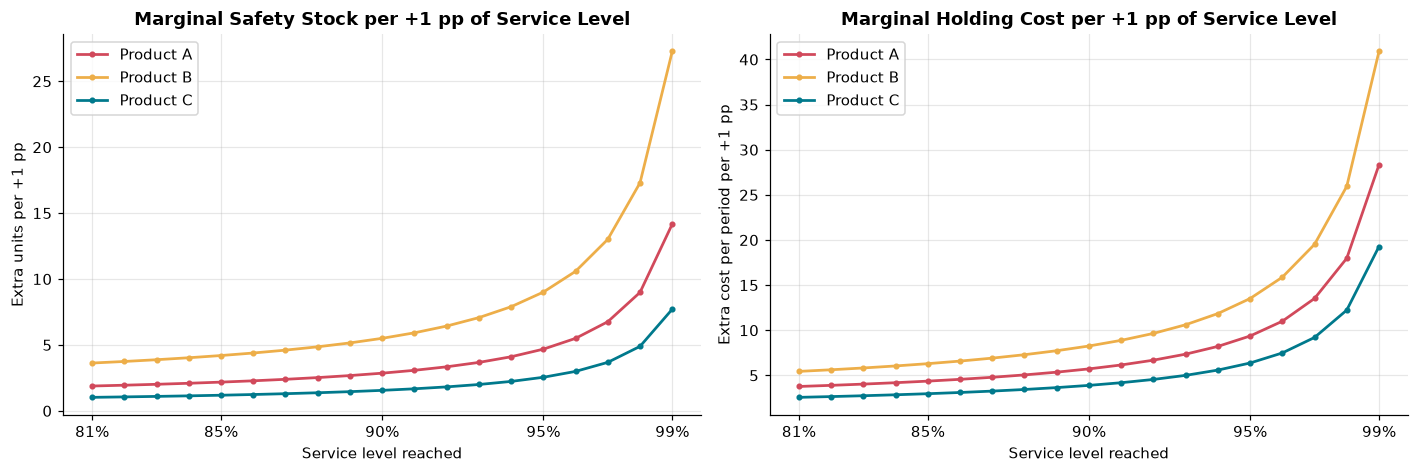

In [23]:
marg = sim.copy()
marg['Marg_SS'] = marg.groupby('Product')['Safety_Stock'].diff()
marg['Marg_HC'] = marg.groupby('Product')['Holding_Cost'].diff()

step = pd.DataFrame({
    p: {'Delta SS 80->90 (10 pp)': at.loc[(p, 0.90), 'Safety_Stock'] - at.loc[(p, 0.80), 'Safety_Stock'],
        'Delta SS 90->99 (9 pp)':  at.loc[(p, 0.99), 'Safety_Stock'] - at.loc[(p, 0.90), 'Safety_Stock'],
        'Marginal SS per +1pp @80-81%': marg[(marg.Product == p) & (np.isclose(marg.Service_Level, 0.81))]['Marg_SS'].iloc[0],
        'Marginal SS per +1pp @98-99%': marg[(marg.Product == p) & (np.isclose(marg.Service_Level, 0.99))]['Marg_SS'].iloc[0],
        'Marginal HC per +1pp @98-99%': marg[(marg.Product == p) & (np.isclose(marg.Service_Level, 0.99))]['Marg_HC'].iloc[0]}
    for p in 'ABC'}).round(1)
display(step)
ratio = (marg[np.isclose(marg.Service_Level, 0.99)]['Marg_SS'].values / marg[np.isclose(marg.Service_Level, 0.81)]['Marg_SS'].values)
put('marg_ratio', ratio[0])
for p in 'ABC':
    put(f'B_{p}_marg_hc_99', step.loc['Marginal HC per +1pp @98-99%', p]); put(f'B_{p}_d_80_90', step.loc['Delta SS 80->90 (10 pp)', p])
    put(f'B_{p}_d_90_99', step.loc['Delta SS 90->99 (9 pp)', p])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for p, c in zip('ABC', [PAL['A'], PAL['B'], PAL['C']]):
    d = marg[marg.Product == p].dropna()
    axes[0].plot(d['Service_Level'], d['Marg_SS'], marker='o', ms=3, lw=1.8, color=c, label=f'Product {p}')
    axes[1].plot(d['Service_Level'], d['Marg_HC'], marker='o', ms=3, lw=1.8, color=c, label=f'Product {p}')
axes[0].set_title('Marginal Safety Stock per +1 pp of Service Level'); axes[0].set_ylabel('Extra units per +1 pp')
axes[1].set_title('Marginal Holding Cost per +1 pp of Service Level'); axes[1].set_ylabel('Extra cost per period per +1 pp')
for a in axes:
    a.set_xlabel('Service level reached'); a.set_xticks([0.81, 0.85, 0.90, 0.95, 0.99])
    a.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=0)); a.legend()
plt.tight_layout(); plt.savefig('outputs/B6_marginal_cost.png', dpi=150, bbox_inches='tight'); plt.show()

**Business interpretation – non-linearity and marginal cost.**
- **Non-linear growth is confirmed numerically.** The 80 → 90 % step (10 points) adds 22.9 / 44.0 / 12.4 units for A / B / C, but the 90 → 99 % step (only 9 points) adds 54.3 / 104.5 / 29.6 units – **about 2.4× more** with fewer points.
- The marginal safety stock of the last point (98 → 99 %) is ≈ **7.5 times** the marginal stock of the first point (80 → 81 %) for every product (e.g. A: 1.9 → 14.2 units per point; B: 3.6 → 27.3).
- The marginal holding cost of the last point is 28.3 (A), **40.9 (B)** and 19.3 (C) per period: the 99th point is far more expensive than the 81st for every product, and most expensive for the volatile Product B. This is the "diminishing returns" curve that the recommendation below is built on.

**(c) Recommended service level per product.** Because no stock-out (shortage) cost was provided, I use a transparent planner rule: *raise the service level step by step while the extra holding cost of the next +1 pp stays at or below a tolerance of **15 currency units per period**.* The tolerance is an assumption, so its effect is tested at 10 / 15 / 25. The recommended points are then marked on the same trade-off curves (visual check) and compared with uniform 95 % and uniform 99 % policies for the whole portfolio.

Recommendation with tolerance = 15 currency units per +1 pp:


,Recommended SL,Safety stock (units),Holding cost / period,Extra cost to reach 99%,Marginal HC of last step
A,97%,97.70,195.50,46.30,13.50
B,95%,164.50,246.70,102.20,13.50
C,98%,58.10,145.20,19.30,12.20


Sensitivity of the recommendation to the tolerance:


,tol=10,tol=15,tol=25
A,95%,97%,98%
B,92%,95%,97%
C,97%,98%,99%


,Total safety stock (units),Total holding cost / period
Uniform 95%,296.50,534.00
Recommended,320.30,587.40
Uniform 99%,419.30,755.20


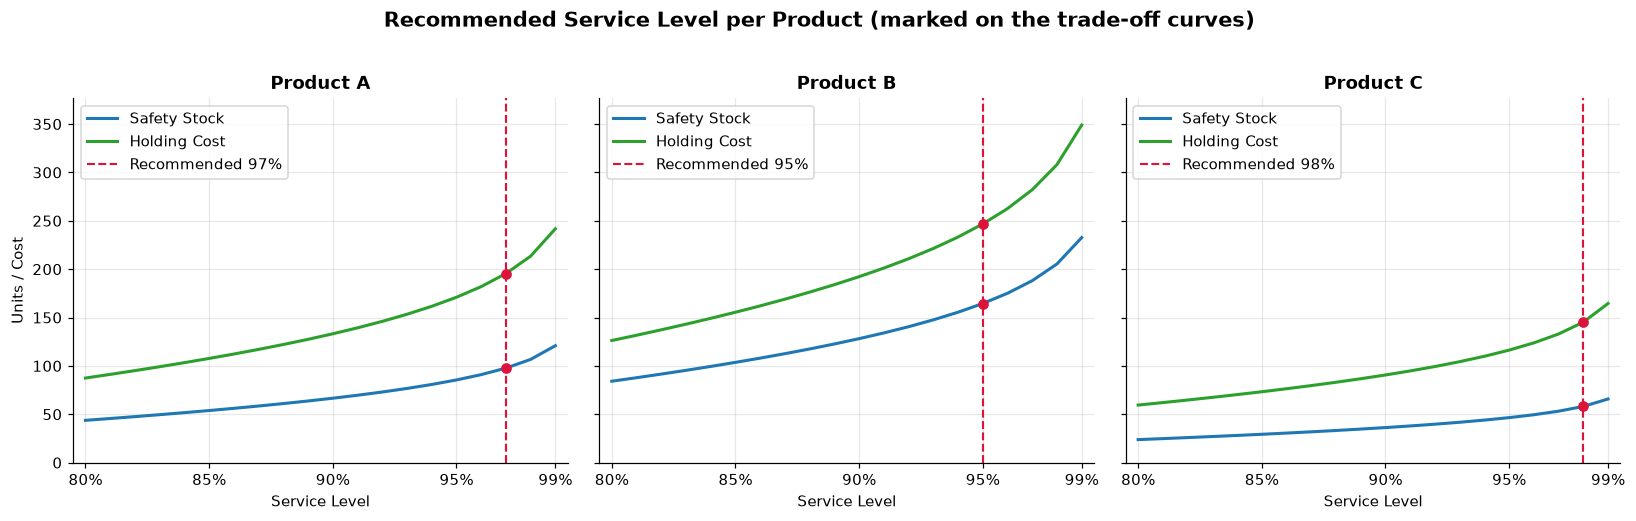

In [24]:
def recommend(tol):
    out = {}
    for p in 'ABC':
        d = marg[marg.Product == p].dropna()
        ok = d[d['Marg_HC'] <= tol]
        out[p] = float(ok['Service_Level'].max()) if len(ok) else 0.80      # highest level whose last step is affordable
    return out

TOL = 15
rec = recommend(TOL)
rec_tbl = pd.DataFrame({
    'Recommended SL': [f'{rec[p]:.0%}' for p in 'ABC'],
    'Safety stock (units)': [at.loc[(p, rec[p]), 'Safety_Stock'] for p in 'ABC'],
    'Holding cost / period': [at.loc[(p, rec[p]), 'Holding_Cost'] for p in 'ABC'],
    'Extra cost to reach 99%': [at.loc[(p, 0.99), 'Holding_Cost'] - at.loc[(p, rec[p]), 'Holding_Cost'] for p in 'ABC'],
    'Marginal HC of last step': [marg[(marg.Product == p) & np.isclose(marg.Service_Level, rec[p])]['Marg_HC'].iloc[0] for p in 'ABC'],
}, index=list('ABC')).round(1)
print(f"Recommendation with tolerance = {TOL} currency units per +1 pp:")
display(rec_tbl)
sens = pd.DataFrame({f'tol={t}': {p: f'{recommend(t)[p]:.0%}' for p in 'ABC'} for t in (10, 15, 25)})
print("Sensitivity of the recommendation to the tolerance:")
display(sens)

# portfolio comparison
def port(levels):
    return (sum(at.loc[(p, levels[p]), 'Safety_Stock'] for p in 'ABC'), sum(at.loc[(p, levels[p]), 'Holding_Cost'] for p in 'ABC'))
policies = {'Uniform 95%': {p: 0.95 for p in 'ABC'}, 'Recommended': rec, 'Uniform 99%': {p: 0.99 for p in 'ABC'}}
pol = pd.DataFrame({k: port(v) for k, v in policies.items()}, index=['Total safety stock (units)', 'Total holding cost / period']).T
display(pol.round(1))
for p in 'ABC':
    put(f'rec_{p}', rec[p]); put(f'rec_{p}_ss', at.loc[(p, rec[p]), 'Safety_Stock']); put(f'rec_{p}_hc', at.loc[(p, rec[p]), 'Holding_Cost'])
for k, v in policies.items():
    kk = k.replace(' ', '_').replace('%', '')
    put(f'pol_{kk}_ss', port(v)[0]); put(f'pol_{kk}_hc', port(v)[1])

# visual check: recommended points on the trade-off curves
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for ax, p in zip(axes, 'ABC'):
    d = sim[sim.Product == p]
    ax.plot(d['Service_Level'], d['Safety_Stock'], color=BLUE, lw=2, label='Safety Stock')
    ax.plot(d['Service_Level'], d['Holding_Cost'], color=GREEN, lw=2, label='Holding Cost')
    ax.axvline(rec[p], color='crimson', ls='--', lw=1.4, label=f'Recommended {rec[p]:.0%}')
    ax.scatter([rec[p]] * 2, [at.loc[(p, rec[p]), 'Safety_Stock'], at.loc[(p, rec[p]), 'Holding_Cost']], color='crimson', zorder=5)
    ax.set_title(f'Product {p}'); ax.set_xlabel('Service Level'); ax.set_xlim(0.795, 0.995)
    ax.set_xticks([0.80, 0.85, 0.90, 0.95, 0.99])
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=0)); ax.legend(loc='upper left')
axes[0].set_ylabel('Units / Cost'); axes[0].set_ylim(0, ymax * 1.08)
fig.suptitle('Recommended Service Level per Product (marked on the trade-off curves)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout(); plt.savefig('outputs/B6_recommended_service_levels.png', dpi=150, bbox_inches='tight'); plt.show()

**Business interpretation – recommended service levels (tolerance = 15 cost units per extra point).**

| Product | Profile | Recommended service level | Safety stock | Holding cost / period |
|---|---|---|---|---|
| **A** | high volume, stable (CV 7.5 %) | **97 %** | 97.7 units | 195.5 |
| **B** | volatile (CV 20 %), long lead time | **95 %** | 164.5 units | 246.7 |
| **C** | low volume, short lead time, dearest to hold | **98 %** | 58.1 units | 145.2 |

- **Product C → 98 %:** the buffer is small (≈ 58 units), so protecting customers is cheap in absolute terms; going to 99 % would cost only 19 extra per period. High service is affordable.
- **Product A → 97 %:** a high-volume, stable fast mover where stock-outs hurt most revenue; the buffer stays moderate (≈ 98 units) and 99 % would add 46 per period, which is only worth it if A is strategic.
- **Product B → 95 %:** B's volatility (CV 20 %) and 4-period lead time make every extra point the most expensive (up to 40.9 per point at 99 %); reaching 99 % would cost 102 more per period. A 95 % policy is the sensible ceiling, and the better lever is to *attack the causes* – improve the forecast, shorten the lead time or pool stock – rather than add buffer.
- **Portfolio view:** the recommended mix holds 320 units at a holding cost of 587 per period – **168 (≈ 22 %) cheaper than a uniform 99 % policy (755)** and only 53 (≈ 10 %) more than a uniform 95 % policy (534), while giving A and C a higher service level.
- **How robust is this?** The tolerance is a planner assumption: with a stricter tolerance of 10 the levels drop to 95 / 92 / 97 % and with a looser 25 they rise to 98 / 97 / 99 % (A / B / C), but the **ranking C ≥ A ≥ B never changes**. If the real stock-out cost per unit were known, it would replace this tolerance (newsvendor logic).

## B7. Sensitivity of Safety Stock to Lead Time and Demand Variability
At a fixed **95 % service level** (Z from `norm.ppf(0.95)`), I vary one driver at a time and then both together:
1. **Lead time** from 1 to 12 periods (σ held at its base value).
2. **Demand variability** – σ scaled from 0.5× to 2× its base value (lead time held at base).
3. **Heat-maps** of safety stock over a lead-time × coefficient-of-variation grid for each product.

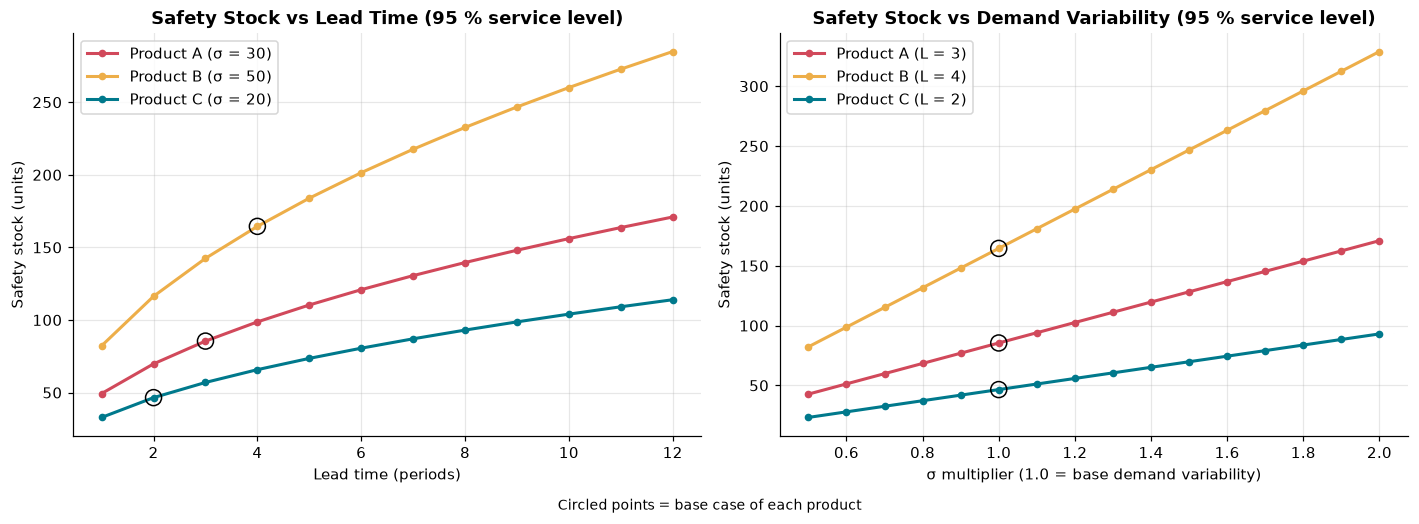

Relative effect on safety stock (identical for every product because SS = Z x sigma x sqrt(L)):


,Change in driver,Safety stock change %
0,Lead time +25%,11.80
1,Lead time x2,41.40
2,Lead time x4,100.00
3,Std dev +25%,25.00
4,Std dev x2,100.00


Safety stock (units) at 95 % for different lead times:


,A,B,C
L=1,49.30,82.20,32.90
L=2,69.80,116.30,46.50
L=4,98.70,164.50,65.80
L=6,120.90,201.50,80.60
L=9,148.00,246.70,98.70
L=12,170.90,284.90,114.00


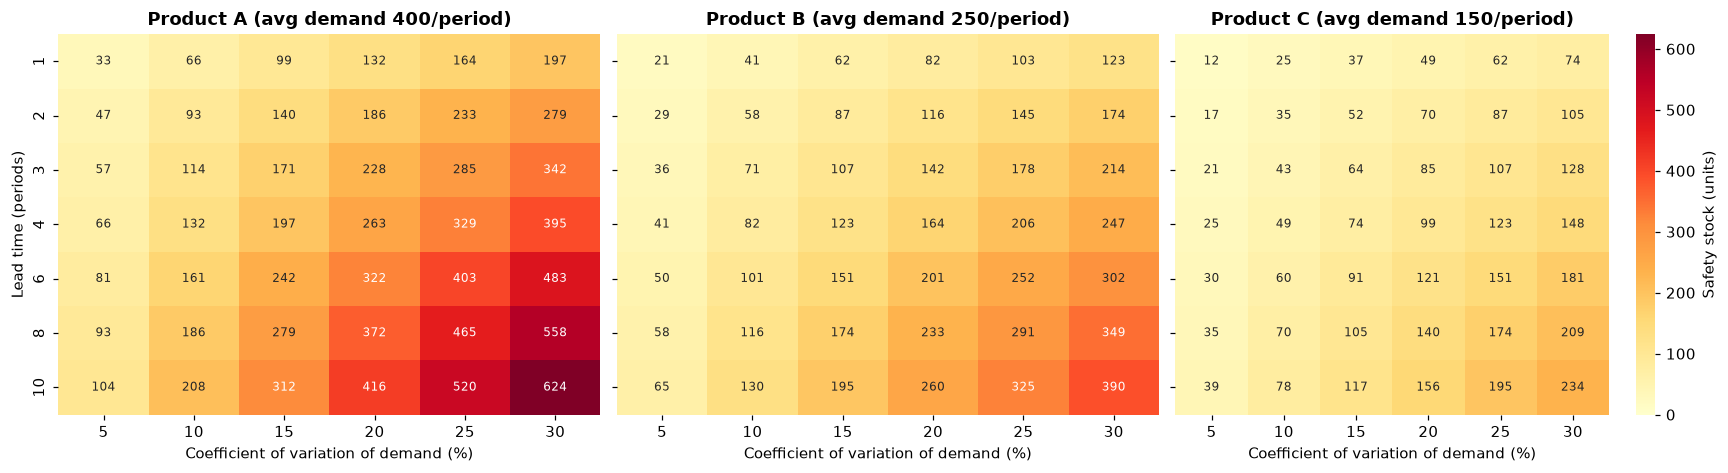

In [25]:
z95 = norm.ppf(0.95)
lt_grid = np.arange(1, 13)
mult_grid = np.round(np.linspace(0.5, 2.0, 16), 2)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for p, c in zip('ABC', [PAL['A'], PAL['B'], PAL['C']]):
    r = products.loc[p]
    axes[0].plot(lt_grid, z95 * r['Demand_Std'] * np.sqrt(lt_grid), marker='o', ms=4, lw=2, color=c, label=f'Product {p} (σ = {r["Demand_Std"]:.0f})')
    axes[0].scatter([r['Lead_Time']], [z95 * r['Demand_Std'] * np.sqrt(r['Lead_Time'])], s=110, facecolors='none', edgecolors='black', zorder=5)
    axes[1].plot(mult_grid, z95 * r['Demand_Std'] * mult_grid * np.sqrt(r['Lead_Time']), marker='o', ms=4, lw=2, color=c,
                 label=f'Product {p} (L = {r["Lead_Time"]:.0f})')
    axes[1].scatter([1.0], [z95 * r['Demand_Std'] * np.sqrt(r['Lead_Time'])], s=110, facecolors='none', edgecolors='black', zorder=5)
axes[0].set_title('Safety Stock vs Lead Time (95 % service level)'); axes[0].set_xlabel('Lead time (periods)'); axes[0].set_ylabel('Safety stock (units)')
axes[1].set_title('Safety Stock vs Demand Variability (95 % service level)'); axes[1].set_xlabel('σ multiplier (1.0 = base demand variability)'); axes[1].set_ylabel('Safety stock (units)')
for a in axes: a.legend()
fig.text(0.5, -0.02, 'Circled points = base case of each product', ha='center', fontsize=9)
plt.tight_layout(); plt.savefig('outputs/B7_sensitivity_curves.png', dpi=150, bbox_inches='tight'); plt.show()

# elasticity table (relative change in safety stock)
el = pd.DataFrame({
    'Change in driver': ['Lead time +25%', 'Lead time x2', 'Lead time x4', 'Std dev +25%', 'Std dev x2'],
    'Safety stock change %': [(np.sqrt(1.25) - 1) * 100, (np.sqrt(2) - 1) * 100, (np.sqrt(4) - 1) * 100, 25.0, 100.0]})
print("Relative effect on safety stock (identical for every product because SS = Z x sigma x sqrt(L)):")
display(el.round(1))
put('el_lt25', el.iloc[0, 1]); put('el_lt2', el.iloc[1, 1]); put('el_lt4', el.iloc[2, 1])

# absolute table
tab = pd.DataFrame({p: {f'L={l}': z95 * products.loc[p, 'Demand_Std'] * np.sqrt(l) for l in (1, 2, 4, 6, 9, 12)} for p in 'ABC'}).round(1)
print("Safety stock (units) at 95 % for different lead times:")
display(tab)
for p in 'ABC':
    put(f'B7_{p}_L1', tab.loc['L=1', p]); put(f'B7_{p}_L12', tab.loc['L=12', p])

# heat-maps: lead time x coefficient of variation
cv_grid = np.array([5, 10, 15, 20, 25, 30])
lt_h = np.array([1, 2, 3, 4, 6, 8, 10])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), sharey=True)
vmax = z95 * (cv_grid.max() / 100) * products['Avg_Demand'].max() * np.sqrt(lt_h.max())
vmax = z95 * (cv_grid.max() / 100) * 400 * np.sqrt(lt_h.max())
for ax, p in zip(axes, 'ABC'):
    mu = products.loc[p, 'Avg_Demand']
    grid = np.array([[z95 * (cv / 100) * mu * np.sqrt(l) for cv in cv_grid] for l in lt_h])
    sns.heatmap(pd.DataFrame(grid, index=lt_h, columns=cv_grid), annot=True, fmt='.0f', cmap='YlOrRd', vmin=0, vmax=vmax,
                cbar=(p == 'C'), cbar_kws={'label': 'Safety stock (units)'}, ax=ax, annot_kws={'size': 8})
    ax.set_title(f'Product {p} (avg demand {mu:.0f}/period)'); ax.set_xlabel('Coefficient of variation of demand (%)'); ax.grid(False)
axes[0].set_ylabel('Lead time (periods)')
plt.tight_layout(); plt.savefig('outputs/B7_sensitivity_heatmaps.png', dpi=150, bbox_inches='tight'); plt.show()

**Business interpretation – sensitivity.**
- **Lead time (concave, square-root curve):** doubling lead time raises safety stock by only **41.4 %** (not 100 %) and quadrupling it by 100 %. From L = 1 to L = 12 the buffer at 95 % grows from 49.3 to 170.9 units for A, 82.2 → 284.9 for B and 32.9 → 114.0 for C. Shortening lead time still helps, but with diminishing returns the shorter it gets.
- **Demand variability (linear):** safety stock is directly proportional to σ – a 25 % rise in volatility raises the buffer by 25 % and a doubling raises it by 100 %. **Demand variability is therefore a much stronger lever than lead time** (σ ×2 → +100 % vs lead time ×2 → +41 %).
- The heat-maps show the two drivers together: Product B with a CV of 30 % and a 10-period lead time would need ≈ 390 units at 95 %, whereas A with CV 5 % and one period needs about 33 units. The same pair of drivers explains why B is the most expensive product: it has the highest CV (20 %) *and* the longest lead time (4 periods).
- **Policy implication:** improving forecast accuracy (lower σ) and negotiating shorter lead times both cut the buffer *without* lowering the service level – an alternative to simply accepting a lower service level.

---
## B8. Before AI vs After AI – Comparison of Plots *(requested by the professor)*
**Before (traditional):** one rule of thumb for the whole range – *"serve every product at 95 %"*.
**After (data-driven):** a **differentiated** service level per product, found from the simulation of safety stock and holding cost and its marginal-cost analysis (B6c: A 97 %, B 95 %, C 98 %). *The uniform 99 % policy is shown as a reference for "maximum service".*

Besides safety stock and holding cost, I add the **expected shortage per replenishment cycle** so the benefit of a higher service level is visible too. With lead-time demand N(μL, σ√L) and safety stock z·σ√L, the expected units short per cycle are σ√L · [φ(z) − z·(1 − Φ(z))] (the standard normal loss function).

Per product:


,Policy,Product,Service_Level,Safety_Stock,Holding_Cost,Stockout_Prob_per_Cycle,Units_Short_per_Cycle
0,Before AI: uniform 95 %,A,0.95,85.47,170.94,0.05,1.09
1,Before AI: uniform 95 %,B,0.95,164.49,246.73,0.05,2.09
2,Before AI: uniform 95 %,C,0.95,46.52,116.31,0.05,0.59
3,After AI: differentiated,A,0.97,97.73,195.46,0.03,0.60
4,After AI: differentiated,B,0.95,164.49,246.73,0.05,2.09
5,After AI: differentiated,C,0.98,58.09,145.22,0.02,0.21
6,Reference: uniform 99 %,A,0.99,120.88,241.76,0.01,0.18
7,Reference: uniform 99 %,B,0.99,232.63,348.95,0.01,0.34
8,Reference: uniform 99 %,C,0.99,65.80,164.50,0.01,0.10


Portfolio totals:


,Total_Safety_Stock,Total_Holding_Cost,Total_Units_Short_per_Cycle
Policy,,,
Before AI: uniform 95 %,296.48,533.97,3.77
After AI: differentiated,320.30,587.41,2.90
Reference: uniform 99 %,419.31,755.21,0.61


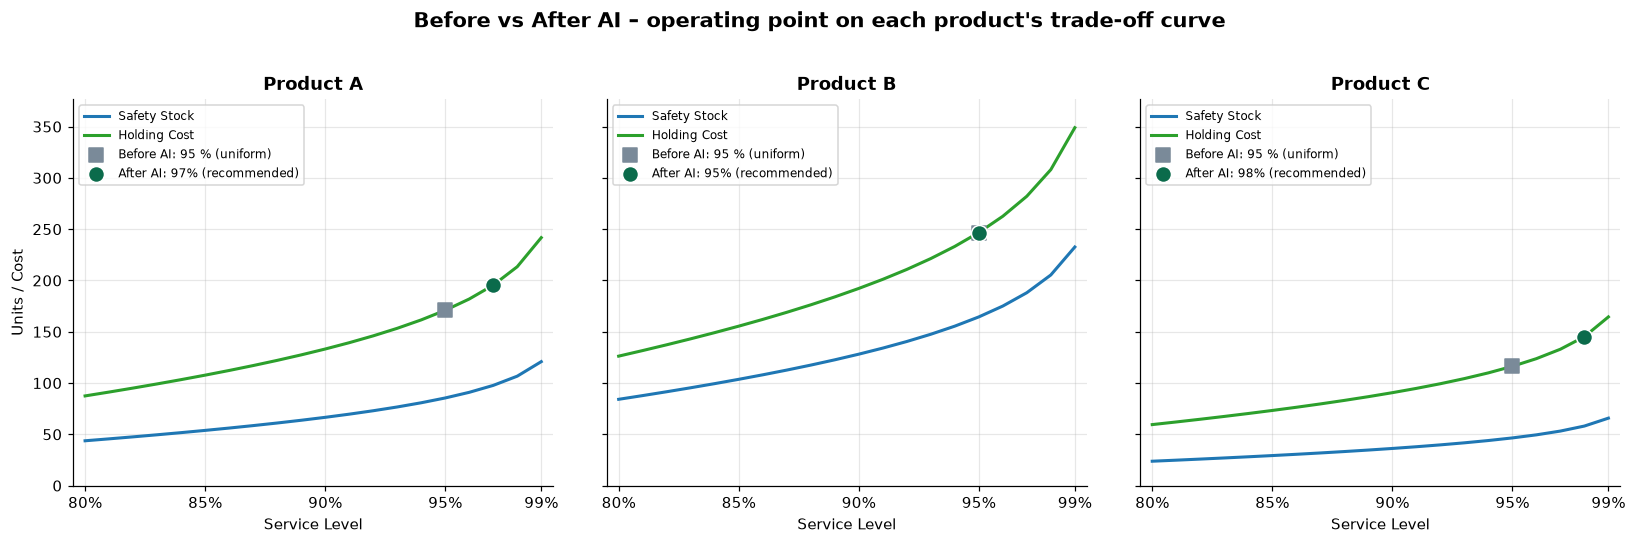

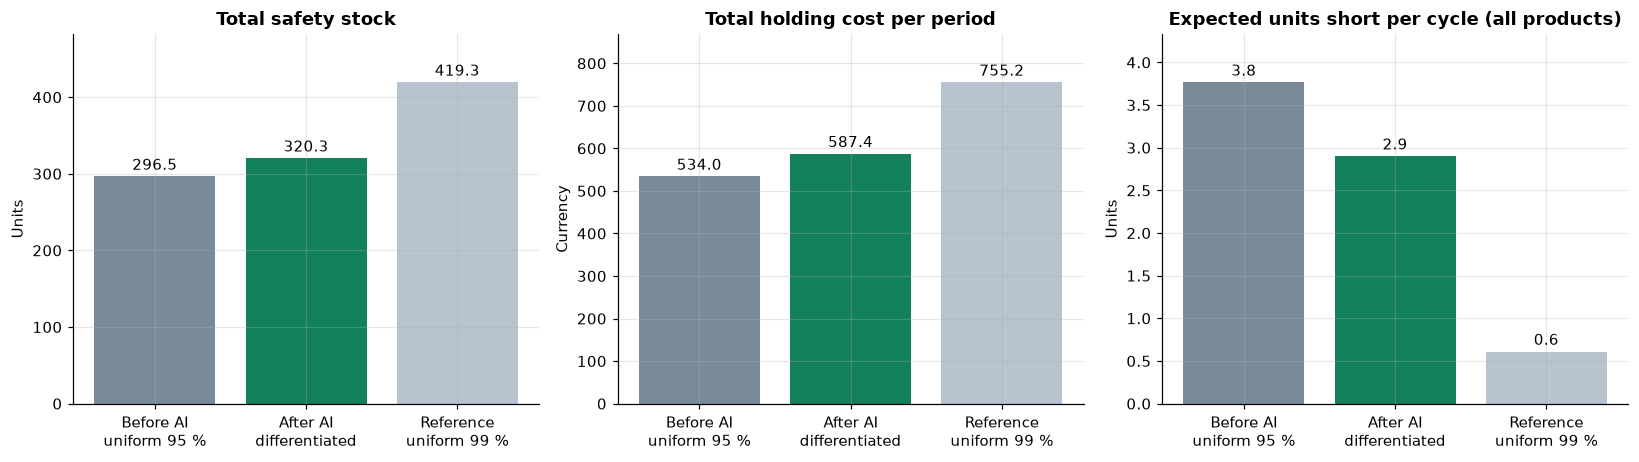

In [26]:
def loss_fn(z):                                            # standard normal loss function  E[(Z - z)+]
    return norm.pdf(z) - z * (1 - norm.cdf(z))

policies_b8 = {'Before AI: uniform 95 %': {p: 0.95 for p in 'ABC'},
               'After AI: differentiated': dict(rec),
               'Reference: uniform 99 %': {p: 0.99 for p in 'ABC'}}
rows = []
for name, lv in policies_b8.items():
    for p in 'ABC':
        r = products.loc[p]; s = lv[p]; z = norm.ppf(s)
        sd_lt = r['Demand_Std'] * np.sqrt(r['Lead_Time']); ss = z * sd_lt
        short = sd_lt * loss_fn(z)
        rows.append({'Policy': name, 'Product': p, 'Service_Level': s, 'Z': z, 'Safety_Stock': ss, 'Holding_Cost': ss * r['Holding_Cost'],
                     'Stockout_Prob_per_Cycle': 1 - s, 'Units_Short_per_Cycle': short,
                     'Short_%_of_LT_Demand': short / (r['Avg_Demand'] * r['Lead_Time']) * 100})
b8 = pd.DataFrame(rows)
print("Per product:")
display(b8[['Policy', 'Product', 'Service_Level', 'Safety_Stock', 'Holding_Cost', 'Stockout_Prob_per_Cycle', 'Units_Short_per_Cycle']].round(3))
tot = b8.groupby('Policy', sort=False).agg(Total_Safety_Stock=('Safety_Stock', 'sum'), Total_Holding_Cost=('Holding_Cost', 'sum'),
                                          Total_Units_Short_per_Cycle=('Units_Short_per_Cycle', 'sum'))
print("Portfolio totals:")
display(tot.round(2))
keys = ['b95', 'after', 'b99']
for k, (nm, rowt) in zip(keys, tot.iterrows()):
    put(f'ba_B_{k}_ss', rowt['Total_Safety_Stock']); put(f'ba_B_{k}_hc', rowt['Total_Holding_Cost']); put(f'ba_B_{k}_short', rowt['Total_Units_Short_per_Cycle'])
for k, nm in zip(keys, policies_b8):
    for p in 'ABC':
        r_ = b8[(b8.Policy == nm) & (b8.Product == p)].iloc[0]
        put(f'ba_B_{k}_{p}_short', r_['Units_Short_per_Cycle']); put(f'ba_B_{k}_{p}_sl', r_['Service_Level'])

# ---- Figure 1: the three product curves with the BEFORE and AFTER operating points -------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
for ax, p in zip(axes, 'ABC'):
    d = sim[sim.Product == p]
    ax.plot(d['Service_Level'], d['Safety_Stock'], color=BLUE, lw=2, label='Safety Stock')
    ax.plot(d['Service_Level'], d['Holding_Cost'], color=GREEN, lw=2, label='Holding Cost')
    ax.scatter([0.95], [at.loc[(p, 0.95), 'Holding_Cost']], marker='s', s=90, color='#7A8A99', zorder=6, label='Before AI: 95 % (uniform)')
    ax.scatter([rec[p]], [at.loc[(p, rec[p]), 'Holding_Cost']], marker='o', s=110, color='#0B6B4B', edgecolor='white', zorder=7, label=f'After AI: {rec[p]:.0%} (recommended)')
    ax.set_title(f'Product {p}'); ax.set_xlabel('Service Level'); ax.set_xlim(0.795, 0.995); ax.set_xticks([0.80, 0.85, 0.90, 0.95, 0.99])
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=0)); ax.legend(loc='upper left', fontsize=8)
axes[0].set_ylabel('Units / Cost'); axes[0].set_ylim(0, ymax * 1.08)
fig.suptitle('Before vs After AI – operating point on each product\'s trade-off curve', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout(w_pad=2.5); plt.savefig('outputs/B8_before_after_curves.png', dpi=150, bbox_inches='tight'); plt.show()

# ---- Figure 2: portfolio comparison ---------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
cols_p = ['#7A8A99', '#12805C', '#B7C4CF']
for ax, col, ttl, unit in [(axes[0], 'Total_Safety_Stock', 'Total safety stock', 'Units'), (axes[1], 'Total_Holding_Cost', 'Total holding cost per period', 'Currency'),
                           (axes[2], 'Total_Units_Short_per_Cycle', 'Expected units short per cycle (all products)', 'Units')]:
    bars = ax.bar(['Before AI\nuniform 95 %', 'After AI\ndifferentiated', 'Reference\nuniform 99 %'], tot[col].values, color=cols_p)
    ax.bar_label(bars, fmt='%.1f', padding=2); ax.set_title(ttl); ax.set_ylabel(unit); ax.set_ylim(0, tot[col].max() * 1.15)
plt.tight_layout(); plt.savefig('outputs/B8_before_after_portfolio.png', dpi=150, bbox_inches='tight'); plt.show()

**Business interpretation – Part B, before vs after AI.**
- **Before (uniform 95 %):** total safety stock 296 units, holding cost 534 per period, **3.77 expected units short per cycle** across the three products.
- **After (A 97 %, B 95 %, C 98 %):** 320 units and 587 per period – **+53 (+10 %) holding cost**, but expected shortage falls to **2.90 units (−23 %)**. Product A's shortage drops from 1.09 to 0.60 and Product C's from 0.59 to 0.21; Product B is deliberately left at 95 % (2.09).
- **Reference (uniform 99 %):** shortage only 0.61 but at 755 per period (+41 % vs uniform 95 %) – it buys the lowest risk at the highest price, and most of the extra money goes to the volatile Product B.
- **Reading the curves:** the grey square (before) and green dot (after) sit on the same cost curve; the differentiated policy moves A and C up the curve where the extra points are cheap and leaves B where the next points would be most expensive. Product B still carries **72 % of the remaining expected shortage** – the lever there is lower demand variability or shorter lead time (B7), not more buffer.
- *Caveat:* "after AI" here means a data-driven, simulation-based policy built on my assumed parameters and the 15-unit cost tolerance; it is not trained on real data and the gain is a trade (more cost for less shortage), not a free improvement.

## Saving the Results
All result tables and the key metrics are written to the relative folder `outputs/` so they can be reused (for example in the one-page summary).

In [27]:
df_out = df[['Item', 'Annual_Usage', 'Unit_Cost', 'Lead_Time', 'Past_Demand', 'Annual_Value', 'Cumulative%',
             'ABC_Category', 'Predicted_ABC', 'Predicted_Demand', 'Std_Dev', 'Safety_Stock']]
df_out.to_csv('outputs/partA_abc_forecast_safety_stock.csv', index=False)
sim.to_csv('outputs/partB_service_level_tradeoff.csv', index=False)
with open('outputs/metrics.json', 'w') as f:
    json.dump(metrics, f, indent=2)
print("Saved files:")
for fn in sorted(os.listdir('outputs')):
    print(f"  outputs/{fn}  ({os.path.getsize(os.path.join('outputs', fn)) / 1024:,.1f} KB)")
print(f"\n{len(metrics)} key metrics stored in outputs/metrics.json")

Saved files:
  outputs/A2_confusion_matrix_feature_importance.png  (58.7 KB)
  outputs/A2_decision_tree.png  (241.3 KB)
  outputs/A3_actual_vs_predicted.png  (113.0 KB)
  outputs/A5_category_distribution.png  (89.5 KB)
  outputs/A5_pareto_chart.png  (86.9 KB)
  outputs/A5_safety_stock_levels.png  (91.7 KB)
  outputs/A7_before_after_classification.png  (93.3 KB)
  outputs/A7_before_after_forecast.png  (126.9 KB)
  outputs/A7_before_after_safety_stock.png  (184.6 KB)
  outputs/B5_service_level_tradeoffs.png  (101.8 KB)
  outputs/B6_marginal_cost.png  (111.0 KB)
  outputs/B6_recommended_service_levels.png  (116.0 KB)
  outputs/B7_sensitivity_curves.png  (136.9 KB)
  outputs/B7_sensitivity_heatmaps.png  (142.3 KB)
  outputs/B8_before_after_curves.png  (118.6 KB)
  outputs/B8_before_after_portfolio.png  (72.1 KB)
  outputs/metrics.json  (6.9 KB)
  outputs/partA_abc_forecast_safety_stock.csv  (38.1 KB)
  outputs/partB_service_level_tradeoff.csv  (3.7 KB)

208 key metrics stored in outputs/me

## Export for the dashboards
One file, `dashboard_data.json`, holds every number the two dashboards (Next.js and Streamlit) display, so they always show exactly what this notebook computed. The tables are also saved as CSV files in `outputs/`.

In [28]:
import datetime
def recs(frame, nd=4):
    return json.loads(frame.round(nd).to_json(orient='records'))

items = df.copy()
items['Rank'] = np.arange(1, len(items) + 1)
items['Tree_Split'] = np.where(items.index.isin(X_test.index), 'test', 'train')
items['LR_Split'] = np.where(items.index.isin(yr_test.index), 'test', 'train')
item_cols = ['Rank', 'Item', 'Annual_Usage', 'Unit_Cost', 'Lead_Time', 'Past_Demand', 'Annual_Value', 'Value_Share%', 'Cumulative%',
             'ABC_Category', 'Predicted_ABC', 'Traditional_ABC', 'Predicted_Demand', 'Std_Dev', 'Safety_Stock', 'SS_Value',
             'SS_Before', 'CSL_Before', 'CSL_After', 'Tree_Split', 'LR_Split']
items_out = items[item_cols]
items_out.round(4).to_csv('outputs/abc_table.csv', index=False)
items[['Item', 'Past_Demand', 'Annual_Usage', 'Predicted_Demand', 'LR_Split']].to_csv('outputs/forecast_table.csv', index=False)
items[['Item', 'ABC_Category', 'Predicted_Demand', 'Std_Dev', 'Lead_Time', 'Safety_Stock', 'SS_Value']].to_csv('outputs/safety_stock_table.csv', index=False)
products.reset_index().to_csv('outputs/partB_parameters.csv', index=False)
b8.round(4).to_csv('outputs/partB_before_after.csv', index=False)
sc.reset_index().rename(columns={'index': 'Metric'}).round(4).to_csv('outputs/partA_before_after_safety_stock.csv', index=False)
fc_cmp.reset_index().rename(columns={'index': 'Metric'}).round(4).to_csv('outputs/partA_before_after_forecast.csv', index=False)
cls_cmp.reset_index().rename(columns={'index': 'Metric'}).round(4).to_csv('outputs/partA_before_after_classification.csv', index=False)

tree_metrics = {'depth': int(best_depth), 'leaves': int(tree.get_n_leaves()), 'train_n': int(len(X_train)), 'test_n': int(len(X_test)),
                'acc_train': float(acc_train), 'acc_test': float(acc_test), 'labels': labels, 'confusion': cm.tolist(),
                'report': {k: {m_: float(v_) for m_, v_ in d.items()} if isinstance(d, dict) else float(d) for k, d in rep.items()},
                'importances': [{'feature': f_, 'importance': float(v_)} for f_, v_ in imp.items()],
                'depth_cv': recs(depth_tbl, 4), 'cv_folds': 5}
json.dump(tree_metrics, open('outputs/tree_metrics.json', 'w'), indent=2)

dash = {
  'meta': {'name': 'Krishna Mathur', 'enrollment_id': 'AS25DXB018', 'program': 'MAIB, September 2025', 'course': 'AI in Operations',
           'professor': 'Prof. Dr. Sandip Kumar Roy', 'task': 'Day 4 - Inventory Management and Optimization, Lab Activity + Lab Exercise',
           'date': '13 November 2026', 'seed': SEED, 'synthetic': True,
           'note': 'Part A data are SYNTHETIC (seed 42). Part B parameters are assumptions calibrated to the reference chart.'},
  'metrics': {k: v for k, v in metrics.items()},
  'abc_summary': recs(abc.reset_index().rename(columns={'ABC_Category': 'Category'}).drop(columns=['Reference (items / value)'])),
  'items': recs(items_out),
  'tree': tree_metrics,
  'forecast': {'coef': float(reg.coef_[0]), 'intercept': float(reg.intercept_), 'r2_test': float(r2_te), 'mae_test': float(mae_te),
               'rmse_test': float(rmse_te), 'r2_train': float(r2_tr), 'mae_train': float(mae_tr), 'rmse_train': float(rmse_tr),
               'coef_all': float(reg_all.coef_[0]), 'intercept_all': float(reg_all.intercept_)},
  'safety_stock': {'z_95': Z_95, 'sigma_pct': 10, 'by_class': recs(ss_sum.reset_index().rename(columns={'ABC_Category': 'Category'})),
                   'total': float(total_ss), 'total_value': float(ssv.sum())},
  'partB': {'parameters': recs(products.reset_index()), 'service_levels': [float(s) for s in service_levels],
            'curves': recs(sim, 4),
            'recommendation': {'tolerance': TOL, 'levels': {p: float(rec[p]) for p in 'ABC'}, 'sensitivity': sens.to_dict()},
            'policies': recs(pol.reset_index().rename(columns={'index': 'Policy'}), 3),
            'before_after': recs(b8, 4), 'before_after_totals': recs(tot.reset_index(), 4)},
  'before_after': {
      'classification': {'before': {'accuracy': float(acc_trad), 'macro_f1': float(rep_trad['macro avg']['f1-score']), 'recall_A': float(recallA_trad), 'confusion': cm_trad.tolist()},
                         'after': {'accuracy': float(acc_test), 'macro_f1': float(rep['macro avg']['f1-score']), 'recall_A': float(recallA_ai), 'confusion': cm.tolist()}},
      'forecast': {'before': {k.split(' (')[0]: float(v) for k, v in fc_cmp.iloc[:, 0].items()}, 'after': {k.split(' (')[0]: float(v) for k, v in fc_cmp.iloc[:, 1].items()},
                   'points': [{'item': it, 'actual': float(actual_t[it]), 'before': float(naive_t[it]), 'after': float(ai_t[it])} for it in yr_test.index]},
      'safety_stock': {'flat_pct': float(flat_pct * 100), 'summary': {r_: {'before': float(sc.loc[r_].iloc[0]), 'after': float(sc.loc[r_].iloc[1])} for r_ in sc.index}}},
  'generated_by': 'AS25DXB018_Krishna_Mathur_Day4_Inventory_Management.ipynb (executed, seed 42)'}
for path in ('outputs/dashboard_data.json', 'data/dashboard_data.json'):
    with open(path, 'w') as f:
        json.dump(dash, f, separators=(',', ':'))
print(f"dashboard_data.json written: {os.path.getsize('outputs/dashboard_data.json') / 1024:,.0f} KB | items: {len(items_out)} | curves: {len(sim)} rows")
print("Also saved: abc_table.csv, forecast_table.csv, safety_stock_table.csv, partB_parameters.csv, partB_before_after.csv, tree_metrics.json, partA_before_after_*.csv")

dashboard_data.json written: 227 KB | items: 500 | curves: 60 rows
Also saved: abc_table.csv, forecast_table.csv, safety_stock_table.csv, partB_parameters.csv, partB_before_after.csv, tree_metrics.json, partA_before_after_*.csv


## Conclusion

**Part A.** ABC analysis of the 500 synthetic SKUs gave a clean Pareto structure: **103 class-A items (20.6 %) hold 70.0 % of the annual value**, class B 20.0 % and class C (51.0 % of the items) only 10.0 %. A decision tree learned to predict the class from the four item features with **90.7 % test accuracy** (macro-F1 0.886), making errors only between neighbouring classes, and a linear regression forecast demand with **R² = 0.991** (MAE 60.6 units). Feeding the forecast into Z · σ · √LT with Z = 1.65 gives a total safety stock of **125,273 units**, of which class A holds 49 % of the units and about 70 % of the buffer value.

**Part B.** For three products with different volatility, lead time and holding cost, raising the service level from 95 % to 99 % increases safety stock and holding cost by **41.4 %** each, while the marginal cost of the last point is about 7.5 times that of the first. A uniform 99 % policy would cost ≈ 755 per period against ≈ 587 for the recommended differentiated policy (**A 97 %, B 95 %, C 98 %**), i.e. ≈ 22 % cheaper. Demand variability (linear) is a stronger lever on the buffer than lead time (square-root).

## Key Takeaways

1. **Prioritise:** about a fifth of the SKUs carries 70 % of the value – focus control, forecasting effort and service level on class A.
2. **ML complements, it does not replace, ABC analysis:** the decision tree reproduces the ABC rule with ≈ 91 % test accuracy and is useful for labelling *new* items; borderline B items still need a human check.
3. **Forecasts feed buffers:** a regression forecast (R² ≈ 0.99) turns directly into safety-stock parameters, but on this data it improved on the naive "same as last year" forecast by only ≈ 2 % in MAE.
4. **Service level is not free:** safety stock grows with Z, which is convex in the service level – +4 points (95 → 99 %) costs **+41 %** in buffer and holding cost for every product.
5. **Differentiate service levels by product:** high-volume stable items (A) and cheap-to-protect items (C) justify 97–98 %; the volatile, long-lead-time Product B is best held at 95 %, with effort put into reducing its variability.
6. **Reduce the drivers, not just the service level:** buffer ∝ σ and ∝ √L, so better forecasts and shorter lead times cut inventory without hurting customers.

## Limitations

- **Synthetic data.** Part A uses generated data (seed 42), not real retail records; all numbers illustrate the method only. The generator was tuned so the ABC split resembles the textbook proportions, so that match is by construction.
- **Dataset size and test-set noise.** I first generated 200 SKUs; with only 60 test items the tree scored ≈ 78 % and results changed a lot with the sample size. I therefore enlarged the data to 500 SKUs (150 test items) for a more stable estimate. Even so, a single split is noisy – a ±3–5 point swing in accuracy would not be surprising.
- **The ABC label is a deterministic rule** (usage × cost, cumulative thresholds), so the classifier approximates a rule it could compute exactly; its value lies in speed for new items, not in discovering new classes. The tree also overfits slightly (train 0.997 vs test 0.907).
- **Simple forecast model.** One predictor (last year's demand), no trend, seasonality, price or promotions; R² is inflated by how the synthetic data was built, and the improvement over a naive forecast is small (1.8 % in MAE).
- **σ = 10 % of predicted demand is assumed**, not estimated from forecast errors, and the lead time is used in the same unit as the demand, as in the professor's code – which is why buffers come out at ≈ 29 % of annual demand. A strict implementation would convert σ to the lead-time period.
- **Normal, independent demand** during the lead time; no lead-time variability, no supplier unreliability, no demand correlation between periods.
- **Part B parameters and the 15-units-per-point tolerance are my assumptions**; no stock-out (shortage) cost was available, so the recommended service levels are policy suggestions, not cost-optimal solutions. The relative increase from 95 % to 99 % (+41.4 %) is identical for all products by construction.
- **Holding cost** is only the cost of the safety-stock units; order cost, cycle stock and obsolescence are not modelled.

## References

1. Roy, S. K. (2026). *Inventory Management and Optimization* – Day 4 lecture slides and sample Colab notebook, AI in Operations, MAIB (September 2025), 13 November 2026.
2. Silver, E. A., Pyke, D. F., & Thomas, D. J. (2017). *Inventory and Production Management in Supply Chains* (4th ed.). CRC Press. (ABC analysis, safety stock, cycle service level.)
3. Chopra, S., & Meindl, P. (2016). *Supply Chain Management: Strategy, Planning, and Operation* (6th ed.). Pearson. (Safety stock and service-level trade-off.)
4. Nahmias, S., & Olsen, T. L. (2015). *Production and Operations Analysis* (7th ed.). Waveland Press.
5. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
6. Virtanen, P. et al. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods, 17*, 261–272.
7. Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95.
8. The Investors Book – Inventory Management (https://theinvestorsbook.com/inventory-management.html), as cited on slide 7 of the lecture.